<h2>IS453 Financial Analytics</h2><h2>Group Assignment - Home Improvement Loan Scorecard</h2>

### Step 5: Grouping and Screening

This notebook follows `04_Data_Preparation.ipynb`. We take the 30 candidate characteristics in `data/prepared_data.csv`, fine-class each one, and measure how well it predicts default on its own with Weight of Evidence (WOE) and Information Value (IV). We follow the **Week 10 Lab**: `pd.qcut` fine classing, `woe_iv`, `woe_iv_plot` and IV screening.

**How this notebook is organised**

| Part | What we do |
|---|---|
| **A - Fine classing and IV screening** (5.1-5.8A) | Train/test split, fine classing of all 30 characteristics on the training sample, IV ranking, and our KEEP / DROP / INVESTIGATE recommendations |
| **B - Candidates for coarse classing** (5.8B) | The screening decisions we agreed as a team: 14 candidates go forward |
| **C - Coarse classing and final selection** (5.8C-5.8D) | Monotonic coarse groups for the 14 candidates, fine vs coarse IV, our final 12 characteristics, and export of `data/final_characteristics.csv` and the groups |

**Rules we follow in this notebook**

- We calculate every bin, WOE and IV on the **training sample only**. We set the test sample aside and do not look at its outcomes.
- We do not remove any characteristic without a team decision, and we do not train a logistic regression here.
- We do not just take the "top 15" by IV: every recommendation has a reason, and we agreed each one as a team.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scorecardpy as sc
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 60)
pd.set_option('display.max_rows', 200)
pd.set_option('display.max_colwidth', 160)
pd.set_option('display.float_format', '{:,.4f}'.format)
plt.rcParams['figure.dpi'] = 80

## 5.1 Business Context

Not every characteristic separates good and bad applicants equally well. Before coarse classing and logistic regression, we screen each characteristic on its own, as we learnt in Week 10:

- **Fine classing** cuts a characteristic into many small groups (bins) so we can see the shape of its relationship with default.
- **WOE** measures how much more (or less) likely a bin's applicants are to be good than the portfolio as a whole: `WOE = ln(% of goods / % of bads)`. A positive WOE means lower risk than average; a negative WOE means higher risk.
- **IV** adds up the WOE differences across all bins, weighted by how many goods and bads fall in each, into one number per characteristic: `IV = sum((% of goods - % of bads) x WOE)`.

The IV scale from the Week 10 lecture:

| IV | Predictive strength |
|---|---|
| IV < 0.02 | No predictive power |
| 0.02 <= IV < 0.10 | Weak |
| 0.10 <= IV < 0.30 | Medium |
| 0.30 <= IV <= 0.50 | Strong |
| IV > 0.50 | Needs checking (suspiciously strong) |

## 5.2 Load the Prepared Data

`data/prepared_data.csv` holds `SK_ID_CURR`, `TARGET` and our 30 candidate characteristics, with genuine missing values left missing (Step 4). We read it here and **do not change it**.

In [2]:
prepared = pd.read_csv('data/prepared_data.csv')

ID, TARGET = 'SK_ID_CURR', 'TARGET'
characteristics = [c for c in prepared.columns if c not in (ID, TARGET)]

print('Rows:', f'{prepared.shape[0]:,}', '| Columns:', prepared.shape[1])
print('Candidate characteristics:', len(characteristics))
print('Unique applicants:', f'{prepared[ID].nunique():,}')
print('Bads:', f'{int(prepared[TARGET].sum()):,}', '| Bad rate:', f'{prepared[TARGET].mean():.2%}')

Rows: 213,312 | Columns: 32
Candidate characteristics: 30
Unique applicants: 213,312
Bads: 16,983 | Bad rate: 7.96%


In [3]:
# fingerprint of the input, re-checked at the end of the notebook to prove it was not changed
def fingerprint(df):
    return int(pd.util.hash_pandas_object(df, index=False).sum() % (2**61))

prepared_fingerprint = fingerprint(prepared)
print('Input fingerprint:', prepared_fingerprint)

Input fingerprint: 1419213447904051780


## 5.3 Train/Test Split

We split the data as in the **Week 11 Lab**: `sc.split_df` with a 70/30 ratio, stratified on `TARGET` so both samples keep the same bad rate, using the scorecardpy default seed (186) so the split can be repeated exactly.

From here on, every grouping, WOE and IV calculation uses the **training sample only**. We keep the test sample for the final model validation. We save its applicant IDs to `data/train_test_split.csv`, so every later step uses exactly the same split.

In [4]:
SPLIT_RATIO, SPLIT_SEED = 0.7, 186

with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    train, test = sc.split_df(prepared, y=TARGET, ratio=SPLIT_RATIO, seed=SPLIT_SEED).values()

split_ids = pd.concat([pd.DataFrame({ID: train[ID], 'SAMPLE': 'train'}),
                       pd.DataFrame({ID: test[ID], 'SAMPLE': 'test'})]).sort_values(ID)
split_ids.to_csv('data/train_test_split.csv', index=False)

split_summary = pd.DataFrame({
    'Applicants': [len(train), len(test), len(prepared)],
    'Bads': [int(train[TARGET].sum()), int(test[TARGET].sum()), int(prepared[TARGET].sum())],
}, index=['Train', 'Test', 'Total'])
split_summary['Share'] = split_summary['Applicants'] / len(prepared)
split_summary['Bad rate'] = split_summary['Bads'] / split_summary['Applicants']
display(split_summary.style.format({'Applicants': '{:,}', 'Bads': '{:,}', 'Share': '{:.1%}', 'Bad rate': '{:.2%}'}))

assert len(train) + len(test) == len(prepared)
assert set(train[ID]).isdisjoint(test[ID])
print('No applicant is in both samples; split IDs saved to data/train_test_split.csv')

# only the training sample is used below; the test sample is not needed in this notebook
test_size = len(test)
del test

,Applicants,Bads,Share,Bad rate
Train,"149,318","11,888",70.0%,7.96%
Test,"63,994","5,095",30.0%,7.96%
Total,"213,312","16,983",100.0%,7.96%


No applicant is in both samples; split IDs saved to data/train_test_split.csv


**What we found**

- The training sample has **149,318 applicants (11,888 bads)** and the test sample **63,994 (5,095 bads)**. Both keep the portfolio bad rate of **7.96%**, as expected from a split stratified on `TARGET`.
- No applicant is in both samples. We do not use the test sample again in this notebook.
- In Step 4 we only estimated medians for invalid values on all applicants, without using `TARGET`. Everything here that uses `TARGET` (bins, WOE, IV) is learnt on the training sample only.

## 5.4 Fine-Classing Method

We use the Week 10 Lab approach, written as reusable functions and applied to every characteristic the same way.

| Characteristic type | How we fine-class it |
|---|---|
| Numeric | `pd.qcut` into **20 equal-frequency bins** (the bin count from the lab's screening exercise), with edges learnt on the training sample |
| Numeric with a heavily repeated value | Any single value held by **5% or more** of training applicants (for example 0 overdue loans, or a credit-to-goods ratio of exactly 1) gets **its own bin**. `pd.qcut` cannot split a repeated value, so without this rule a count like `MICROLOAN_COUNT` (98.6% zeros) would collapse into one bin |
| Very small numeric bins | Any numeric bin with fewer than **1%** of training applicants is merged into its smaller neighbour, because tiny bins give unstable WOE (Week 10 Lab) |
| Text and 0/1 characteristics | One bin per category (no merging yet) |
| Missing values | Their own **`Missing`** bin, as in the lab's `woe_iv`, so we measure the risk of being missing instead of hiding it |

**Zero-event bins.** If a bin has no bads (or no goods), its WOE is infinite. We report these bins instead of hiding them, leave their applicants out of the IV total, and flag the characteristic. If they cover more than 0.5% of training applicants, we mark the IV **Not evaluable**.

**Sensitivity check.** We also calculate IV with **10 bins**, to see whether a characteristic's IV depends heavily on the bin count. That would suggest noise rather than a real signal.

In [5]:
POINT_MASS_SHARE = 0.05     # a value held by >= 5% of applicants gets its own bin
MIN_BIN_SHARE = 0.01        # numeric bins below 1% of applicants are merged
ZERO_CELL_LIMIT = 0.005     # zero-event bins above 0.5% of applicants -> IV not evaluable
MIN_BIN_BADS = 30           # bins with fewer bads than this are flagged as small-event bins


def fmt(v):
    # readable bin edges
    if float(v).is_integer():
        return f'{v:,.0f}'
    if abs(v) >= 1000:
        return f'{v:,.0f}'
    if abs(v) >= 1:
        return f'{v:,.2f}'
    return f'{v:.4f}'


def is_categorical(s):
    # text characteristics and 0/1 flags are classed by category
    return s.dtype == object or s.dropna().nunique() <= 2


def fine_class_edges(x, q=20):
    # equal-frequency edges (Week 10: pd.qcut), learned on the training values only
    s = x.dropna()
    _, edges = pd.qcut(s, q=q, retbins=True, duplicates='drop')
    edges = set(edges)
    # a heavily repeated value gets its own bin: (just below v, v]
    shares = s.value_counts(normalize=True)
    for v in shares[shares >= POINT_MASS_SHARE].index:
        edges.update([np.nextafter(v, -np.inf), v])
    edges = np.array(sorted(edges))
    # merge bins below the minimum size into their smaller neighbour
    while len(edges) > 2:
        codes = pd.cut(s, edges, labels=False, include_lowest=True)
        share = np.bincount(codes.astype(int), minlength=len(edges) - 1) / len(s)
        i = int(share.argmin())
        if share[i] >= MIN_BIN_SHARE:
            break
        if i == 0:
            drop = 1
        elif i == len(share) - 1:
            drop = i
        else:
            drop = i if share[i - 1] <= share[i + 1] else i + 1
        edges = np.delete(edges, drop)
    return edges


def edge_labels(edges, x, codes):
    # a bin that holds a single value is labelled '= value'; otherwise its interval
    lo, hi = x.groupby(codes).min(), x.groupby(codes).max()
    labels = []
    for k, (a, b) in enumerate(zip(edges[:-1], edges[1:])):
        if k in lo.index and lo[k] == hi[k]:
            labels.append(f'= {fmt(hi[k])}')
        elif k == 0:
            labels.append(f'[{fmt(lo[k])}, {fmt(b)}]')
        else:
            labels.append(f'({fmt(a)}, {fmt(b)}]')
    return labels


def fine_class(data, variable, q=20):
    # returns the variable, TARGET and its fine-classing Bin_Range (Missing as its own bin)
    working = data[[variable, TARGET]].copy()
    if is_categorical(working[variable]):
        working['Bin_Range'] = working[variable].astype('object').map(lambda v: v if pd.isna(v) else str(v))
        order = sorted(working['Bin_Range'].dropna().unique())
    else:
        edges = fine_class_edges(working[variable], q=q)
        codes = pd.cut(working[variable], edges, labels=False, include_lowest=True)
        order = edge_labels(edges, working[variable], codes)
        working['Bin_Range'] = codes.map(lambda k: k if pd.isna(k) else order[int(k)])
    working['Bin_Range'] = working['Bin_Range'].fillna('Missing')
    if (working['Bin_Range'] == 'Missing').any():
        order = order + ['Missing']
    working['Bin_Range'] = pd.Categorical(working['Bin_Range'], categories=order, ordered=True)
    return working

In [6]:
# Week 10 Lab woe_iv, extended to keep the bin order and to report zero-event bins instead of returning infinity
def woe_iv(data):
    working_data = data.copy()
    grouped = working_data.groupby('Bin_Range', observed=True)[TARGET]

    variable_data = pd.DataFrame()
    variable_data['Bin_Range'] = grouped.count().index.astype(str)
    variable_data['Count'] = grouped.count().values
    variable_data['Events'] = grouped.sum().values
    variable_data['Non_Events'] = variable_data['Count'] - variable_data['Events']
    variable_data['%_of_Obs'] = variable_data['Count'] / variable_data['Count'].sum()
    variable_data['Bad_Rate'] = variable_data['Events'] / variable_data['Count']
    variable_data['%_of_Events'] = variable_data['Events'] / sum(variable_data['Events'])
    variable_data['%_of_Non_Events'] = variable_data['Non_Events'] / sum(variable_data['Non_Events'])

    # zero-event (or zero-non-event) bins have infinite WOE: report them, leave them out of the IV total
    variable_data['Zero_Cell'] = (variable_data['Events'] == 0) | (variable_data['Non_Events'] == 0)
    valid = ~variable_data['Zero_Cell']
    variable_data['WOE'] = np.nan
    variable_data.loc[valid, 'WOE'] = np.log(variable_data.loc[valid, '%_of_Non_Events'] / variable_data.loc[valid, '%_of_Events'])
    variable_data['IV'] = (variable_data['%_of_Non_Events'] - variable_data['%_of_Events']) * variable_data['WOE']
    variable_data['total_IV'] = variable_data['IV'].sum()
    return variable_data


# Week 10 Lab woe_iv_plot: WOE line over the bins, Missing as a separate point, bars = % of applicants
def woe_iv_plot(variable_data, variable_name, iv_text, categorical):
    fig, ax1 = plt.subplots(figsize=(15, 4.8))
    x = np.arange(len(variable_data))
    is_missing = (variable_data['Bin_Range'] == 'Missing').values

    ax2 = ax1.twinx()
    ax2.bar(x, variable_data['%_of_Obs'] * 100, alpha=0.35, color='deepskyblue', label='% of applicants')
    ax2.set_ylabel('Percent of Observations (%)')

    ax1.set_zorder(ax2.get_zorder() + 1)
    ax1.patch.set_visible(False)
    woe = variable_data['WOE'].values
    if categorical:
        ax1.plot(x[~is_missing], woe[~is_missing], 'o', color='tab:blue', markersize=7, label='WOE')
    else:
        ax1.plot(x[~is_missing], woe[~is_missing], '-o', color='tab:blue', label='WOE')
    if is_missing.any():
        ax1.plot(x[is_missing], woe[is_missing], 's', color='tab:red', markersize=8, label='WOE (Missing bin)')
    zero = variable_data['Zero_Cell'].values
    if zero.any():
        ax1.plot(x[zero], np.zeros(zero.sum()), 'x', color='black', markersize=9, label='Zero-event bin (WOE infinite)')
    ax1.axhline(0, color='grey', linewidth=0.8, linestyle='--')
    ax1.set_ylabel('WOE  (+ lower risk / - higher risk)')
    ax1.set_xticks(x)
    ax1.set_xticklabels(variable_data['Bin_Range'], rotation=45, ha='right', fontsize=8)
    ax1.legend(loc='best', fontsize=8)
    plt.title(f'WOE plot for {variable_name}  ({iv_text})')
    plt.tight_layout()
    plt.show()

**WOE trend rule.** For numeric characteristics, the WOE of the ordered bins (excluding `Missing`) is compared with the bin order using the Spearman rank correlation:

| Spearman rho of WOE vs bin order | WOE trend |
|---|---|
| WOE moves in the same direction at every step | Monotonic |
| \|rho\| >= 0.8 | Mostly monotonic |
| 0.5 <= \|rho\| < 0.8 | Weak trend |
| \|rho\| < 0.5 | Non-monotonic |

Because a positive WOE means lower risk, "WOE rises with value" means **risk falls as the value rises**. For text and 0/1 characteristics there is no order, so the lowest- and highest-risk categories are reported instead.

In [7]:
def woe_trend(variable_data, categorical):
    t = variable_data[(variable_data['Bin_Range'] != 'Missing') & variable_data['WOE'].notnull()]
    if len(t) < 2:
        return 'Single bin (no trend)'
    if categorical:
        hi = t.loc[t['WOE'].idxmin(), 'Bin_Range']
        lo = t.loc[t['WOE'].idxmax(), 'Bin_Range']
        return f'Categories: highest risk "{hi}", lowest risk "{lo}"'
    woe = t['WOE'].values
    direction = 'risk falls as value rises' if woe[-1] > woe[0] else 'risk rises as value rises'
    steps = np.sign(np.diff(woe))
    if len(woe) == 2 or (steps != 0).all() and (np.all(steps > 0) or np.all(steps < 0)):
        return f'Monotonic: {direction}'
    rho = pd.Series(woe).corr(pd.Series(np.arange(len(woe))), method='spearman')
    direction = 'risk falls as value rises' if rho > 0 else 'risk rises as value rises'
    if abs(rho) >= 0.8:
        return f'Mostly monotonic (rho {rho:+.2f}): {direction}'
    if abs(rho) >= 0.5:
        return f'Weak trend (rho {rho:+.2f}): {direction}'
    return f'Non-monotonic (rho {rho:+.2f})'


def iv_class(iv):
    if pd.isna(iv):
        return 'Not evaluable'
    if iv < 0.02:
        return 'No predictive power'
    if iv < 0.10:
        return 'Weak'
    if iv < 0.30:
        return 'Medium'
    if iv <= 0.50:
        return 'Strong'
    return 'Requires further investigation'

## 5.5 Fine Classing of All 30 Characteristics (training sample)

We fine-class each characteristic on the training sample, build its WOE table and calculate its IV. The checks we record for each one feed the investigation flags in 5.6A.

In [8]:
fine_tables, rows = {}, []
for variable in characteristics:
    categorical = is_categorical(train[variable])
    variable_data = woe_iv(fine_class(train, variable, q=20))
    fine_tables[variable] = variable_data

    zero_share = variable_data.loc[variable_data['Zero_Cell'], '%_of_Obs'].sum()
    iv = variable_data['total_IV'].iloc[0] if zero_share <= ZERO_CELL_LIMIT else np.nan
    iv_10 = woe_iv(fine_class(train, variable, q=10))['total_IV'].iloc[0]
    missing_row = variable_data[variable_data['Bin_Range'] == 'Missing']
    rows.append({
        'Characteristic': variable,
        'Type': 'Categorical' if categorical else 'Numeric',
        'Fine IV': iv,
        'IV (10 bins)': iv_10,
        'Missing %': train[variable].isna().mean(),
        'Number of bins': len(variable_data),
        'Smallest bin %': variable_data['%_of_Obs'].min(),
        'Fewest bads in a bin': int(variable_data['Events'].min()),
        'Zero-event bins': int(variable_data['Zero_Cell'].sum()),
        'Zero-event applicants %': zero_share,
        'Missing-bin IV share': (missing_row['IV'].sum() / variable_data['IV'].sum()) if len(missing_row) and variable_data['IV'].sum() > 0 else 0.0,
        'Missing-bin WOE': missing_row['WOE'].iloc[0] if len(missing_row) else np.nan,
        'WOE trend': woe_trend(variable_data, categorical),
    })

screen = pd.DataFrame(rows)
screen['Predictive strength'] = screen['Fine IV'].map(iv_class)
print('Characteristics fine-classed:', len(screen), 'of', len(characteristics))
display(screen.drop(columns=['WOE trend']).set_index('Characteristic').style.format({
    'Fine IV': '{:.4f}', 'IV (10 bins)': '{:.4f}', 'Missing %': '{:.2%}', 'Smallest bin %': '{:.2%}',
    'Zero-event applicants %': '{:.3%}', 'Missing-bin IV share': '{:.1%}', 'Missing-bin WOE': '{:+.3f}'}, na_rep='-'))

Characteristics fine-classed: 30 of 30


,Type,Fine IV,IV (10 bins),Missing %,Number of bins,Smallest bin %,Fewest bads in a bin,Zero-event bins,Zero-event applicants %,Missing-bin IV share,Missing-bin WOE,Predictive strength
Characteristic,,,,,,,,,,,,
AMT_INCOME_TOTAL,Numeric,0.0106,0.0093,0.00%,20,1.20%,141,0,0.000%,0.0%,-,No predictive power
AMT_CREDIT,Numeric,0.0570,0.0434,0.00%,20,2.89%,300,0,0.000%,0.0%,-,Weak
LOAN_TO_INCOME,Numeric,0.0113,0.0101,0.00%,20,4.30%,452,0,0.000%,0.0%,-,No predictive power
ANNUITY_TO_INCOME,Numeric,0.0067,0.0056,0.00%,21,0.00%,0,1,0.001%,0.0%,-,No predictive power
CREDIT_TO_ANNUITY_RATIO,Numeric,0.1664,0.1188,0.00%,21,0.00%,0,1,0.001%,0.0%,-,Medium
CREDIT_TO_GOODS_RATIO,Numeric,0.1005,0.0942,0.10%,16,0.10%,10,0,0.000%,0.0%,+0.184,Medium
NAME_CONTRACT_TYPE,Categorical,0.0164,0.0164,0.00%,2,10.87%,887,0,0.000%,0.0%,-,No predictive power
EMPLOYMENT_YEARS,Numeric,0.1185,0.1159,19.80%,21,4.00%,254,0,0.000%,26.6%,+0.437,Medium
FLAG_DAYS_EMPLOYED_SPECIAL,Categorical,0.0377,0.0377,0.00%,2,19.80%,1565,0,0.000%,0.0%,-,Weak


**Investigation flags.** As well as the IV class, we check each characteristic for stability and data-quality problems. A flag does not mean the characteristic is bad; it means we look more closely before accepting its result.

| Flag | Rule |
|---|---|
| IV above 0.50 | Suspiciously strong for one characteristic; check for leakage |
| Zero-event bin | A bin with no bads or no goods (infinite WOE) |
| Small-event bin | A bin with fewer than 30 bads, so its WOE rests on very few defaults |
| High missingness | More than 30% of training applicants missing |
| Missing bin drives IV | More than 50% of the IV comes from the `Missing` bin, so the signal is "has data / has no data" rather than the value itself |
| Unstable numeric WOE | Numeric WOE trend classed as Non-monotonic |
| IV sensitive to bin count | IV with 10 bins differs from IV with 20 bins by more than 25% |
| Possible leakage | Could only be known after the loan decision (judged from its definition) |

In [9]:
# characteristics that could only be known after the application (none of the 30 by definition: the
# application fields are captured at application and the bureau fields come from credits before it)
POSSIBLE_LEAKAGE = []


def investigation_flags(r):
    flags = []
    if r['Fine IV'] > 0.50:
        flags.append('IV above 0.50')
    if r['Zero-event bins'] > 0:
        flags.append('Zero-event bin')
    if r['Fewest bads in a bin'] < MIN_BIN_BADS and r['Zero-event bins'] == 0:
        flags.append('Small-event bin')
    if r['Missing %'] > 0.30:
        flags.append('High missingness')
    if r['Missing-bin IV share'] > 0.50:
        flags.append('Missing bin drives IV')
    if r['WOE trend'].startswith('Non-monotonic'):
        flags.append('Unstable numeric WOE')
    if r['Fine IV'] >= 0.02 and abs(r['IV (10 bins)'] - r['Fine IV']) / r['Fine IV'] > 0.25:
        flags.append('IV sensitive to bin count')
    if r['Characteristic'] in POSSIBLE_LEAKAGE:
        flags.append('Possible leakage')
    return flags


screen['Flags'] = screen.apply(investigation_flags, axis=1)
screen['Flag count'] = screen['Flags'].map(len)
screen['Flags text'] = screen['Flags'].map(lambda f: '; '.join(f) if f else '-')
display(screen[['Characteristic', 'Fine IV', 'Predictive strength', 'Flags text']]
        .rename(columns={'Flags text': 'Investigation flags'}).set_index('Characteristic'))

,Fine IV,Predictive strength,Investigation flags
Characteristic,,,
AMT_INCOME_TOTAL,0.0106,No predictive power,Unstable numeric WOE
AMT_CREDIT,0.0570,Weak,Unstable numeric WOE
LOAN_TO_INCOME,0.0113,No predictive power,Unstable numeric WOE
ANNUITY_TO_INCOME,0.0067,No predictive power,Zero-event bin
CREDIT_TO_ANNUITY_RATIO,0.1664,Medium,Zero-event bin; Unstable numeric WOE; IV sensitive to bin count
CREDIT_TO_GOODS_RATIO,0.1005,Medium,Small-event bin
NAME_CONTRACT_TYPE,0.0164,No predictive power,-
EMPLOYMENT_YEARS,0.1185,Medium,-
FLAG_DAYS_EMPLOYED_SPECIAL,0.0377,Weak,-


**Interpretation**

- **All 30 characteristics could be evaluated.** Zero-event bins occur in only three characteristics, and they are tiny:
  - the 2 applicants with a missing annuity (`ANNUITY_TO_INCOME`, `CREDIT_TO_ANNUITY_RATIO`)
  - 14 applicants in the `Businessman` and `Student` categories of `NAME_INCOME_TYPE`

  Together they are far below the 0.5% limit, so no IV had to be marked Not evaluable.
- **Small-event bins** are also tiny categories or tiny Missing bins:
  - `Academic degree` (82 applicants, 1 bad)
  - IT and HR staff in `OCCUPATION_TYPE`
  - the 149 applicants with a missing goods price

  Coarse classing merges these.
- **For several bureau counts, the "signal" is mainly the Missing bin.** For `TOTAL_PROLONGATIONS`, `ADVERSE_STATUS_COUNT`, `TOTAL_BUREAU_ENQUIRIES_12M` and `BUREAU_LOAN_COUNT`, 56%-81% of the IV comes from the 14.7% of applicants with no bureau history (bad rate 9.8%). That is the same information in every bureau characteristic, so it does not show that the count itself predicts default.
- **Non-monotonic WOE** appears for the income and loan-size measures (`AMT_INCOME_TOTAL`, `LOAN_TO_INCOME`, `AMT_CREDIT`), for `BUREAU_LOAN_COUNT`, and for `CREDIT_TO_ANNUITY_RATIO`. For the first two and `BUREAU_LOAN_COUNT`, the IV is so low that the zig-zag is just noise around a flat bad rate.
- **IV is stable to the bin count** for every characteristic except `CREDIT_TO_ANNUITY_RATIO`: its IV falls from 0.166 to 0.119 with 10 bins, because its signal sits in narrow product-specific ranges that wider bins blur.

### Overlap between characteristics (training sample)

IV looks at each characteristic on its own, so two characteristics can both show a signal while carrying the same information. Below we test the overlaps the fine-classing tables suggested, using only the training sample.

In [10]:
ov = {}
ov['FLAG_DAYS_EMPLOYED_SPECIAL = 1'] = int((train['FLAG_DAYS_EMPLOYED_SPECIAL'] == 1).sum())
ov['EMPLOYMENT_YEARS missing'] = int(train['EMPLOYMENT_YEARS'].isna().sum())
ov['... and both at once'] = int(((train['FLAG_DAYS_EMPLOYED_SPECIAL'] == 1) & train['EMPLOYMENT_YEARS'].isna()).sum())
ov['NAME_INCOME_TYPE = Pensioner'] = int((train['NAME_INCOME_TYPE'] == 'Pensioner').sum())
ov['... of whom EMPLOYMENT_YEARS missing'] = int(((train['NAME_INCOME_TYPE'] == 'Pensioner') & train['EMPLOYMENT_YEARS'].isna()).sum())
ov['OCCUPATION_TYPE missing'] = int(train['OCCUPATION_TYPE'].isna().sum())
ov['... of whom Pensioner'] = int((train['OCCUPATION_TYPE'].isna() & (train['NAME_INCOME_TYPE'] == 'Pensioner')).sum())
ov['HAS_BUREAU_HISTORY = 0'] = int((train['HAS_BUREAU_HISTORY'] == 0).sum())
ov['... and BUREAU_LOAN_COUNT missing'] = int(((train['HAS_BUREAU_HISTORY'] == 0) & train['BUREAU_LOAN_COUNT'].isna()).sum())
ov['NAME_CONTRACT_TYPE = Revolving loans'] = int((train['NAME_CONTRACT_TYPE'] == 'Revolving loans').sum())
ov['... of whom CREDIT_TO_ANNUITY_RATIO = 20'] = int(((train['NAME_CONTRACT_TYPE'] == 'Revolving loans') & (train['CREDIT_TO_ANNUITY_RATIO'] == 20)).sum())
ov['CREDIT_TO_ANNUITY_RATIO = 20 (all applicants)'] = int((train['CREDIT_TO_ANNUITY_RATIO'] == 20).sum())
display(pd.DataFrame({'Training applicants': ov}).style.format('{:,}'))

rank_pairs = [('BUREAU_DEBT_TO_INCOME', 'EXISTING_DEBT_SHARE_OF_EXPOSURE'), ('ACTIVE_LOAN_COUNT', 'ACTIVE_CREDIT_CARD_COUNT'),
              ('BUREAU_DEBT_TO_INCOME', 'DEBT_TO_CREDIT_RATIO'), ('LOAN_TO_INCOME', 'ANNUITY_TO_INCOME'),
              ('AMT_CREDIT', 'CREDIT_TO_ANNUITY_RATIO'), ('OLDEST_CREDIT_AGE', 'MOST_RECENT_CREDIT_AGE')]
display(pd.DataFrame([{'Characteristic A': a, 'Characteristic B': b,
                       'Spearman rho': train[a].corr(train[b], method='spearman'),
                       'Pearson r': train[a].corr(train[b])} for a, b in rank_pairs]).style.format({'Spearman rho': '{:+.3f}', 'Pearson r': '{:+.3f}'}).hide(axis='index'))

# rare but severe bureau signals: bad rate of applicants with at least one such record
rare = []
for v in ['OVERDUE_LOAN_COUNT', 'MICROLOAN_COUNT', 'ADVERSE_STATUS_COUNT', 'MORTGAGE_COUNT', 'TOTAL_PROLONGATIONS']:
    has = train[v] > 0
    rare.append({'Characteristic': v, 'Applicants with value > 0': int(has.sum()), 'Share': has.mean(),
                 'Bad rate if > 0': train.loc[has, TARGET].mean(), 'Bad rate if = 0': train.loc[train[v] == 0, TARGET].mean(),
                 'Bad rate if missing': train.loc[train[v].isna(), TARGET].mean()})
display(pd.DataFrame(rare).style.format({'Applicants with value > 0': '{:,}', 'Share': '{:.2%}', 'Bad rate if > 0': '{:.2%}',
                                         'Bad rate if = 0': '{:.2%}', 'Bad rate if missing': '{:.2%}'}).hide(axis='index'))

,Training applicants
FLAG_DAYS_EMPLOYED_SPECIAL = 1,"29,563"
EMPLOYMENT_YEARS missing,"29,563"
... and both at once,"29,563"
NAME_INCOME_TYPE = Pensioner,"29,556"
... of whom EMPLOYMENT_YEARS missing,"29,552"
OCCUPATION_TYPE missing,"48,844"
... of whom Pensioner,"29,553"
HAS_BUREAU_HISTORY = 0,"21,981"
... and BUREAU_LOAN_COUNT missing,"21,981"
NAME_CONTRACT_TYPE = Revolving loans,"16,224"


Characteristic A,Characteristic B,Spearman rho,Pearson r
BUREAU_DEBT_TO_INCOME,EXISTING_DEBT_SHARE_OF_EXPOSURE,+0.955,+0.617
ACTIVE_LOAN_COUNT,ACTIVE_CREDIT_CARD_COUNT,+0.728,+0.771
BUREAU_DEBT_TO_INCOME,DEBT_TO_CREDIT_RATIO,+0.588,+0.348
LOAN_TO_INCOME,ANNUITY_TO_INCOME,+0.802,+0.786
AMT_CREDIT,CREDIT_TO_ANNUITY_RATIO,+0.669,+0.666
OLDEST_CREDIT_AGE,MOST_RECENT_CREDIT_AGE,+0.123,+0.197


Characteristic,Applicants with value > 0,Share,Bad rate if > 0,Bad rate if = 0,Bad rate if missing
OVERDUE_LOAN_COUNT,"1,614",1.08%,15.12%,7.55%,9.80%
MICROLOAN_COUNT,"1,752",1.17%,18.55%,7.49%,9.80%
ADVERSE_STATUS_COUNT,"2,575",1.72%,10.21%,7.59%,9.80%
MORTGAGE_COUNT,"7,295",4.89%,5.14%,7.80%,9.80%
TOTAL_PROLONGATIONS,"4,059",2.72%,8.47%,7.62%,9.80%


**Interpretation**

- **`FLAG_DAYS_EMPLOYED_SPECIAL` duplicates `EMPLOYMENT_YEARS`.** All 29,563 applicants with the flag are exactly the applicants with missing employment years. Keeping both would count the same pensioner / no-employer effect twice.
- **`HAS_BUREAU_HISTORY` duplicates the Missing bin of every bureau characteristic.** The 21,981 applicants with no history are exactly those with missing bureau values.
- **`NAME_CONTRACT_TYPE` is captured by `CREDIT_TO_ANNUITY_RATIO`.** 16,197 of the 16,224 revolving loans have a ratio of exactly 20, and only 2 other applicants share that value.
- **Pensioners in `NAME_INCOME_TYPE` and `OCCUPATION_TYPE`.** 29,552 of the 29,556 pensioners have missing employment years, and pensioners make up 60% of the missing occupations. The remaining categories of both characteristics still carry their own information.
- **`BUREAU_DEBT_TO_INCOME` and `EXISTING_DEBT_SHARE_OF_EXPOSURE` rank applicants almost identically** (Spearman 0.955). The Pearson value (0.77) stayed under the Step 4 threshold of 0.8 only because of the different scales. For a binned (WOE) model, the rank correlation is the relevant measure.
- **Rare but severe signals.** Applicants with a current overdue bureau loan (15.1% bad rate) or any microloan (18.6%) default at about twice the 7.5% rate of those without. These groups are small (1.1%-1.2%), so their IV is low, but the effect itself is large. Adverse status (10.2%) and prolongations (8.5%) show much weaker effects, and a mortgage lowers risk (5.1%).

## 5.6A Rank All Characteristics by Predictive Power

We rank all 30 characteristics from highest to lowest fine-classing IV. Each one appears once; any characteristic whose IV could not be calculated reliably would be at the bottom as `Not evaluable`. The recommendation column is explained in 5.6B.

In [11]:
# reviewed recommendations (5.6B): IV class + WOE shape + business relevance + overlap evidence from 5.5
# nothing is removed here; these are our first-pass recommendations
P, C, D, I = 'PRIORITISE RETAINING', 'CONSIDER RETAINING', 'PROPOSE DROPPING', 'INVESTIGATE'
RECOMMENDATIONS = {
    # ---- affordability and loan
    'CREDIT_TO_ANNUITY_RATIO': (I, 'Highest IV (medium), but the WOE zig-zags between neighbouring bins (2.1% vs 13.4% bad rate) and IV drops from 0.166 to 0.119 with 10 bins. '
                                   'The ratio is the implied repayment term, so it reflects product and pricing; if the lender priced by risk, part of its signal may be the lender\'s own risk view. Its only zero-event bin is the 2-applicant Missing bin. Needs a decision on whether to keep it and group it by product term'),
    'CREDIT_TO_GOODS_RATIO': (P, 'Medium IV with a clear trend: financing more than the goods price (insurance or fees added) raises risk, from 6.5% at a ratio of 1 or below to 15.9% above 1.40. Only 0.1% missing'),
    'AMT_CREDIT': (C, 'Weak IV with a consistent hump: mid-sized loans (about 270k-675k) are riskiest, the smallest and largest are safest. Not monotonic, so coarse classing needs low / middle / high groups (as with LOAN in the Week 10 lab)'),
    'AMT_INCOME_TOTAL': (D, 'No predictive power (IV 0.011); bad rate is flat at 7-9% across almost all income bins. Affordability is still covered by the credit-based ratios and bureau debt-to-income'),
    'LOAN_TO_INCOME': (D, 'No predictive power (IV 0.011) and non-monotonic. Highly rank-correlated with ANNUITY_TO_INCOME (0.80) and AMT_CREDIT (0.76), so it adds nothing they do not'),
    'ANNUITY_TO_INCOME': (D, 'No predictive power (IV 0.007): bad rates stay within 7.0-8.9% across all 20 bins. The 2 missing applicants form a zero-event bin of negligible size'),
    'NAME_CONTRACT_TYPE': (D, 'No predictive power (IV 0.016). Redundant: 16,197 of the 16,224 revolving loans have CREDIT_TO_ANNUITY_RATIO exactly 20, and only 2 other applicants share that value, so that bin of CREDIT_TO_ANNUITY_RATIO already identifies revolving loans'),
    # ---- employment and stability
    'EMPLOYMENT_YEARS': (P, 'Medium IV with a near-monotonic trend (rho +0.94): risk falls steadily with years employed (10-12% bad rate under 3 years to 4.3% over 20 years). Its Missing bin is exactly the pensioner / no-employer group (low risk)'),
    'FLAG_DAYS_EMPLOYED_SPECIAL': (D, 'Redundant: flag = 1 identifies exactly the same applicants as the Missing bin of EMPLOYMENT_YEARS (identical WOE +0.437), so EMPLOYMENT_YEARS already carries this information'),
    'NAME_INCOME_TYPE': (C, 'Weak IV. Its strongest category (Pensioner) overlaps almost fully with the EMPLOYMENT_YEARS Missing bin, but it adds State servant (5.7% bad rate) vs Working (9.5%). Four tiny categories (28 applicants, two with zero bads) must be merged in coarse classing'),
    'NAME_EDUCATION_TYPE': (C, 'Weak IV, clear business meaning: Higher education 5.4% bad rate vs Secondary 8.8%. The Academic degree category (82 applicants, 1 bad) must be merged with Higher education in coarse classing'),
    'OCCUPATION_TYPE': (C, 'Weak IV (0.085), close to medium, with a clear spread (Accountants 4.7% to Low-skill Laborers 16.2%). 32.7% missing, but explained: 60% of the missing are pensioners and the rest did not state an occupation. Only 19% of its IV comes from the Missing bin. Small occupations need merging in coarse classing'),
    # ---- housing and assets
    'NAME_HOUSING_TYPE': (D, 'No predictive power (IV 0.008): 93% of the segment is in one category (House / apartment), as expected for home owners'),
    'FLAG_OWN_CAR': (D, 'No predictive power (IV 0.004)'),
    # ---- existing credit exposure
    'HAS_BUREAU_HISTORY': (D, 'Redundant: its 0 group is exactly the Missing bin of every bureau characteristic (same 21,981 training applicants, same WOE). IV only 0.010'),
    'BUREAU_LOAN_COUNT': (D, 'No predictive power (IV 0.015) and non-monotonic; 56% of its small IV comes from the Missing (no bureau) bin, which other bureau characteristics already carry'),
    'ACTIVE_LOAN_COUNT': (C, 'Weak IV with a monotonic trend: risk rises with the number of active loans (5.5% with none to 13.6% with 6+). Rank-correlated 0.73 with ACTIVE_CREDIT_CARD_COUNT'),
    'ACTIVE_LOAN_RATIO': (C, 'Weak IV (0.096), just below medium, with a near-monotonic trend (rho -0.94): a higher share of credits still open means higher risk'),
    'ACTIVE_CREDIT_CARD_COUNT': (C, 'Weak IV with a monotonic trend (6.5% with no active card to 12.7% with 4+). Overlaps with ACTIVE_LOAN_COUNT (rank correlation 0.73); the user may prefer to keep only one of the two'),
    'BUREAU_DEBT_TO_INCOME': (C, 'Weak IV with a near-monotonic trend (rho -0.92). It is the only income-based affordability measure that shows signal, so it represents existing debt burden'),
    'DEBT_TO_CREDIT_RATIO': (C, 'Weak IV with a clean, near-monotonic trend (rho -0.95): utilisation near or above 100% doubles the bad rate (4.9% at 0 vs 12.8%). 34.3% missing, but the missing are applicants with no active credit or no bureau history; the Missing bin contributes only 2% of the IV'),
    'EXISTING_DEBT_SHARE_OF_EXPOSURE': (D, 'Redundant: rank correlation 0.955 with BUREAU_DEBT_TO_INCOME, similar IV (0.052 vs 0.050), and a less consistent WOE trend (rho -0.76, risk falls again in the top bins)'),
    'MORTGAGE_COUNT': (D, 'No predictive power (IV 0.018); 48% of it comes from the Missing bin. Applicants with a mortgage are safer (5.1% vs 7.8%), but they are only 4.9% of applicants'),
    'MICROLOAN_COUNT': (C, 'Weak IV, but a strong signal on a small group: applicants with any microloan default at 18.6% vs 7.5% (1.2% of applicants). Microloans are a recognised sign of financial stress'),
    # ---- delinquency
    'ADVERSE_STATUS_COUNT': (D, 'No predictive power (IV 0.012); 70% of it comes from the Missing bin. Applicants with an adverse status are only modestly riskier (10.2% vs 7.6%)'),
    'OVERDUE_LOAN_COUNT': (C, 'IV just below 0.02, so not dropped automatically: applicants currently overdue on a bureau loan default at 15.1% vs 7.6%, double the risk. It is the only current-arrears measure. The low IV reflects how rare the group is (1.1%), not a weak effect'),
    'TOTAL_PROLONGATIONS': (D, 'No predictive power (IV 0.010); 81% of it comes from the Missing bin. Applicants with prolonged loans are barely riskier (8.5% vs 7.6%)'),
    # ---- credit history
    'OLDEST_CREDIT_AGE': (C, 'Weak IV (0.080) with a near-monotonic trend (rho +0.97): a longer credit history means lower risk'),
    'MOST_RECENT_CREDIT_AGE': (C, 'Weak IV (0.093) with a near-monotonic trend (rho +0.93): recent new credit means higher risk. Distinct from OLDEST_CREDIT_AGE (see rank correlation in 5.5)'),
    'TOTAL_BUREAU_ENQUIRIES_12M': (D, 'No predictive power (IV 0.015); 66% of it comes from the Missing bin. Among applicants with data, bad rate moves only from 7.1% to 9.0% across enquiry counts'),
}

In [12]:
ranking = screen.sort_values('Fine IV', ascending=False, na_position='last').reset_index(drop=True)
ranking.insert(0, 'Rank', np.arange(1, len(ranking) + 1))
ranking['Recommendation'] = ranking['Characteristic'].map(lambda c: RECOMMENDATIONS[c][0])

assert ranking['Characteristic'].is_unique and len(ranking) == len(characteristics)
display(ranking[['Rank', 'Characteristic', 'Fine IV', 'Predictive strength', 'Missing %', 'Number of bins',
                 'WOE trend', 'Recommendation']].set_index('Rank')
        .style.format({'Fine IV': '{:.4f}', 'Missing %': '{:.2%}'}, na_rep='Not evaluable'))

,Characteristic,Fine IV,Predictive strength,Missing %,Number of bins,WOE trend,Recommendation
Rank,,,,,,,
1,CREDIT_TO_ANNUITY_RATIO,0.1664,Medium,0.00%,21,Non-monotonic (rho +0.28),INVESTIGATE
2,EMPLOYMENT_YEARS,0.1185,Medium,19.80%,21,Mostly monotonic (rho +0.94): risk falls as value rises,PRIORITISE RETAINING
3,CREDIT_TO_GOODS_RATIO,0.1005,Medium,0.10%,16,Mostly monotonic (rho -0.91): risk rises as value rises,PRIORITISE RETAINING
4,ACTIVE_LOAN_RATIO,0.0964,Weak,14.72%,17,Mostly monotonic (rho -0.94): risk rises as value rises,CONSIDER RETAINING
5,MOST_RECENT_CREDIT_AGE,0.0932,Weak,14.72%,21,Mostly monotonic (rho +0.93): risk falls as value rises,CONSIDER RETAINING
6,OCCUPATION_TYPE,0.0849,Weak,32.71%,19,"Categories: highest risk ""Low-skill Laborers"", lowest risk ""Accountants""",CONSIDER RETAINING
7,OLDEST_CREDIT_AGE,0.0803,Weak,14.72%,21,Mostly monotonic (rho +0.97): risk falls as value rises,CONSIDER RETAINING
8,ACTIVE_LOAN_COUNT,0.0634,Weak,14.72%,8,Monotonic: risk rises as value rises,CONSIDER RETAINING
9,NAME_INCOME_TYPE,0.0622,Weak,0.00%,8,"Categories: highest risk ""Maternity leave"", lowest risk ""Pensioner""",CONSIDER RETAINING


### Classification summary

In [13]:
classes = ['No predictive power', 'Weak', 'Medium', 'Strong', 'Requires further investigation', 'Not evaluable']
class_counts = ranking['Predictive strength'].value_counts().reindex(classes, fill_value=0)

summary = pd.DataFrame({'Characteristics': class_counts})
summary.loc['Total (primary classification)'] = class_counts.sum()
summary.loc['With at least one stability or data-quality flag'] = int((ranking['Flag count'] > 0).sum())
display(summary)

assert class_counts.sum() == len(characteristics)
print(f'Check: primary classification counts sum to {class_counts.sum()} = {len(characteristics)} characteristics')

,Characteristics
Predictive strength,
No predictive power,13
Weak,14
Medium,3
Strong,0
Requires further investigation,0
Not evaluable,0
Total (primary classification),30
With at least one stability or data-quality flag,14


Check: primary classification counts sum to 30 = 30 characteristics


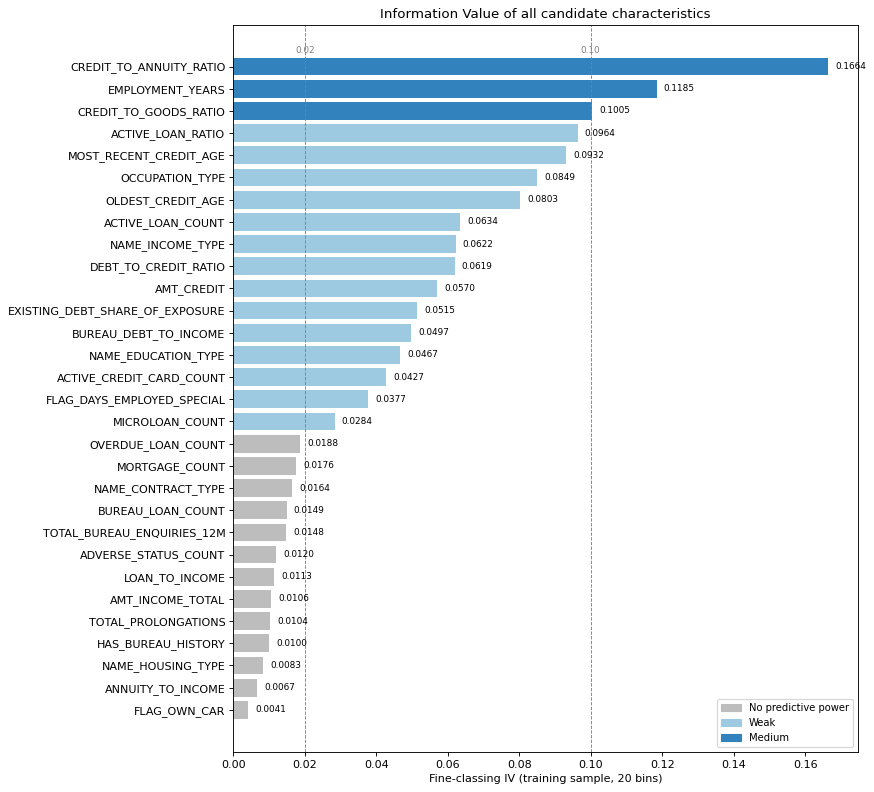

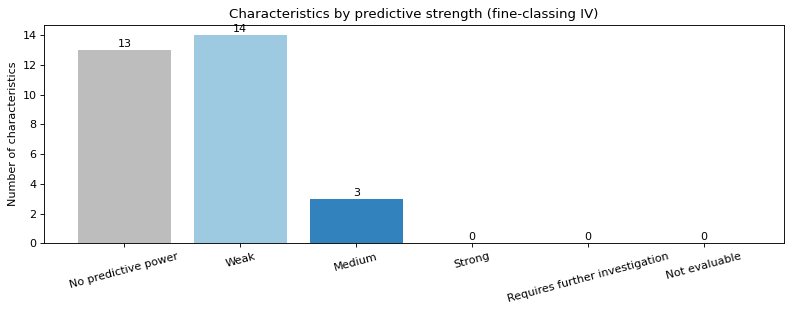

In [14]:
colors = {'No predictive power': '#bdbdbd', 'Weak': '#9ecae1', 'Medium': '#3182bd', 'Strong': '#08519c',
          'Requires further investigation': '#de2d26', 'Not evaluable': '#000000'}

# 1. horizontal bar chart of IV, highest at the top
plot_data = ranking.dropna(subset=['Fine IV']).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 10))
ax.barh(plot_data['Characteristic'], plot_data['Fine IV'], color=plot_data['Predictive strength'].map(colors))
for y, v in enumerate(plot_data['Fine IV']):
    ax.text(v + 0.002, y, f'{v:.4f}', va='center', fontsize=8)
for t, lab in [(0.02, '0.02'), (0.10, '0.10'), (0.30, '0.30'), (0.50, '0.50')]:
    if t <= plot_data['Fine IV'].max() * 1.15:
        ax.axvline(t, color='grey', linestyle='--', linewidth=0.8)
        ax.text(t, len(plot_data) - 0.4, lab, fontsize=8, color='grey', ha='center')
handles = [plt.Rectangle((0, 0), 1, 1, color=colors[c]) for c in classes if (ranking['Predictive strength'] == c).any()]
ax.legend(handles, [c for c in classes if (ranking['Predictive strength'] == c).any()], loc='lower right', fontsize=9)
ax.set_xlabel('Fine-classing IV (training sample, 20 bins)')
ax.set_title('Information Value of all candidate characteristics')
plt.tight_layout()
plt.show()

# 2. number of characteristics in each IV category
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(class_counts.index, class_counts.values, color=[colors[c] for c in class_counts.index])
for x, v in enumerate(class_counts.values):
    ax.text(x, v + 0.2, str(v), ha='center')
ax.set_ylabel('Number of characteristics')
ax.set_title('Characteristics by predictive strength (fine-classing IV)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Characteristics we need to look at more closely

Every characteristic with at least one flag from 5.5, or with IV above 0.50 / not evaluable.

In [15]:
investigate = ranking[(ranking['Flag count'] > 0) | ranking['Predictive strength'].isin(['Requires further investigation', 'Not evaluable'])]
display(investigate[['Rank', 'Characteristic', 'Fine IV', 'Predictive strength', 'Missing %', 'Missing-bin IV share',
                     'Fewest bads in a bin', 'Zero-event bins', 'IV (10 bins)', 'Flags text']]
        .rename(columns={'Flags text': 'Investigation flags'}).set_index('Rank')
        .style.format({'Fine IV': '{:.4f}', 'IV (10 bins)': '{:.4f}', 'Missing %': '{:.2%}', 'Missing-bin IV share': '{:.1%}'}, na_rep='-'))
print(len(investigate), 'characteristics carry at least one investigation flag')

,Characteristic,Fine IV,Predictive strength,Missing %,Missing-bin IV share,Fewest bads in a bin,Zero-event bins,IV (10 bins),Investigation flags
Rank,,,,,,,,,
1,CREDIT_TO_ANNUITY_RATIO,0.1664,Medium,0.00%,0.0%,0,1,0.1188,Zero-event bin; Unstable numeric WOE; IV sensitive to bin count
3,CREDIT_TO_GOODS_RATIO,0.1005,Medium,0.10%,0.0%,10,0,0.0942,Small-event bin
6,OCCUPATION_TYPE,0.0849,Weak,32.71%,19.4%,11,0,0.0849,Small-event bin; High missingness
9,NAME_INCOME_TYPE,0.0622,Weak,0.00%,0.0%,0,2,0.0622,Zero-event bin
10,DEBT_TO_CREDIT_RATIO,0.0619,Weak,34.27%,2.0%,309,0,0.0611,High missingness
11,AMT_CREDIT,0.0570,Weak,0.00%,0.0%,300,0,0.0434,Unstable numeric WOE
14,NAME_EDUCATION_TYPE,0.0467,Weak,0.00%,0.0%,1,0,0.0467,Small-event bin
21,BUREAU_LOAN_COUNT,0.0149,No predictive power,14.72%,56.3%,269,0,0.0134,Missing bin drives IV; Unstable numeric WOE
22,TOTAL_BUREAU_ENQUIRIES_12M,0.0148,No predictive power,13.90%,66.5%,297,0,0.0147,Missing bin drives IV


14 characteristics carry at least one investigation flag


**What we found**

- **None of our characteristics is strong.** 3 are medium, 14 weak and 13 have no predictive power:
  - the highest IV is `CREDIT_TO_ANNUITY_RATIO` at 0.166
  - nothing is above 0.30, so nothing is suspiciously strong (IV > 0.50)
  - this fits our EDA, where the strongest single correlation with `TARGET` was only about 0.16 (`EXT_SOURCE_1`, which we removed in Step 4)

  So our scorecard has to combine many weak-to-medium characteristics instead of relying on a few strong ones.
- **The strongest areas:**
  - loan structure: implied term, and borrowing above the goods price
  - job stability
  - existing credit behaviour: share of credits still open, recency and age of credit, number of active loans
  - occupation
- **The weakest areas:**
  - income-based affordability (`AMT_INCOME_TOTAL`, `LOAN_TO_INCOME`, `ANNUITY_TO_INCOME`): almost flat bad rates, possibly because declared income is not verified
  - housing type and car ownership: little variation among homeowners
  - most bureau arrears counts: rare, and their IV is mostly the shared no-bureau effect
- **14 characteristics have an investigation flag.** Most are tiny bins that coarse classing will fix, or IV driven by the Missing bin in characteristics we are dropping anyway. The one that needs a team decision is `CREDIT_TO_ANNUITY_RATIO` (5.6B).

### Fine-classing WOE graphs and tables (ranking order)

One graph and one binning table per characteristic, in IV order. Blue line and dots: WOE per bin (above 0 = lower risk than average). Red square: the `Missing` bin. Bars: share of training applicants in each bin.

#### 1. CREDIT_TO_ANNUITY_RATIO  
IV = 0.1664, Medium | 21 bins | WOE trend: Non-monotonic (rho +0.28)

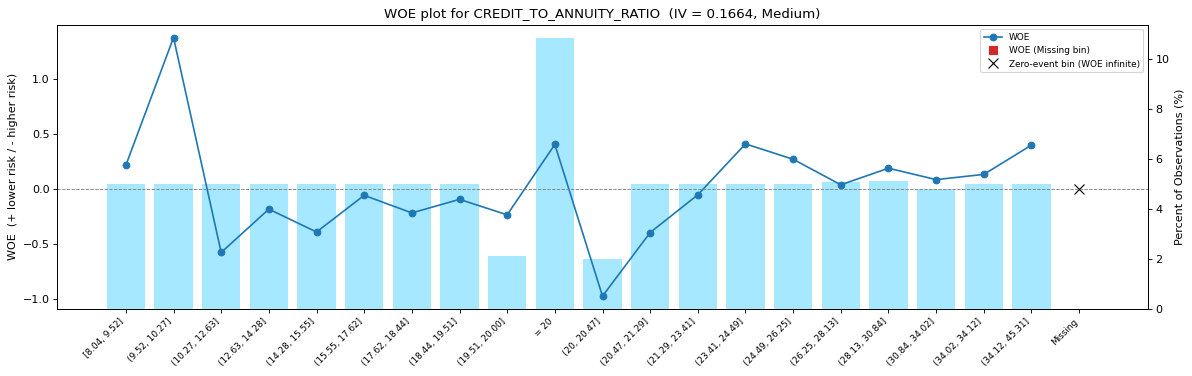

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
"[8.04, 9.52]","7,480",5.01%,489,6.54%,+0.2124,0.0021
"(9.52, 10.27]","7,455",4.99%,160,2.15%,+1.3722,0.0544
"(10.27, 12.63]","7,463",5.00%,999,13.39%,-0.5803,0.0215
"(12.63, 14.28]","7,467",5.00%,705,9.44%,-0.1867,0.0019
"(14.28, 15.55]","7,474",5.01%,850,11.37%,-0.3944,0.0092
"(15.55, 17.62]","7,457",4.99%,628,8.42%,-0.0612,0.0002
"(17.62, 18.44]","7,465",5.00%,727,9.74%,-0.2210,0.0027
"(18.44, 19.51]","7,498",5.02%,653,8.71%,-0.0979,0.0005
"(19.51, 20.00]","3,154",2.11%,312,9.89%,-0.2383,0.0013
= 20,"16,199",10.85%,887,5.48%,+0.4010,0.0148


#### 2. EMPLOYMENT_YEARS  
IV = 0.1185, Medium | 21 bins | WOE trend: Mostly monotonic (rho +0.94): risk falls as value rises

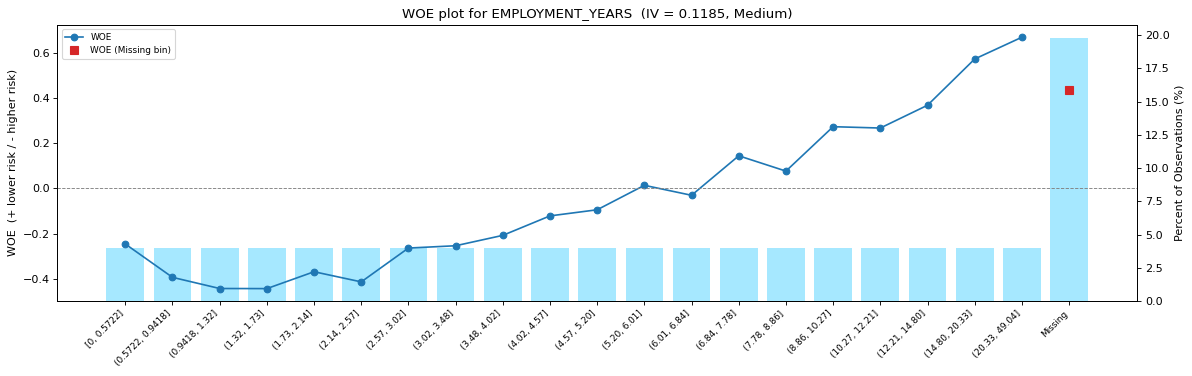

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
"[0, 0.5722]","5,998",4.02%,597,9.95%,-0.2452,0.0027
"(0.5722, 0.9418]","6,024",4.03%,684,11.35%,-0.3926,0.0073
"(0.9418, 1.32]","5,978",4.00%,709,11.86%,-0.4418,0.0094
"(1.32, 1.73]","5,984",4.01%,710,11.86%,-0.4423,0.0094
"(1.73, 2.14]","5,978",4.00%,664,11.11%,-0.3678,0.0063
"(2.14, 2.57]","5,996",4.02%,693,11.56%,-0.4126,0.0081
"(2.57, 3.02]","5,971",4.00%,604,10.12%,-0.2631,0.0031
"(3.02, 3.48]","5,996",4.02%,601,10.02%,-0.2530,0.0029
"(3.48, 4.02]","5,979",4.00%,575,9.62%,-0.2071,0.0019
"(4.02, 4.57]","5,981",4.01%,532,8.89%,-0.1210,0.0006


#### 3. CREDIT_TO_GOODS_RATIO  
IV = 0.1005, Medium | 16 bins | WOE trend: Mostly monotonic (rho -0.91): risk rises as value rises

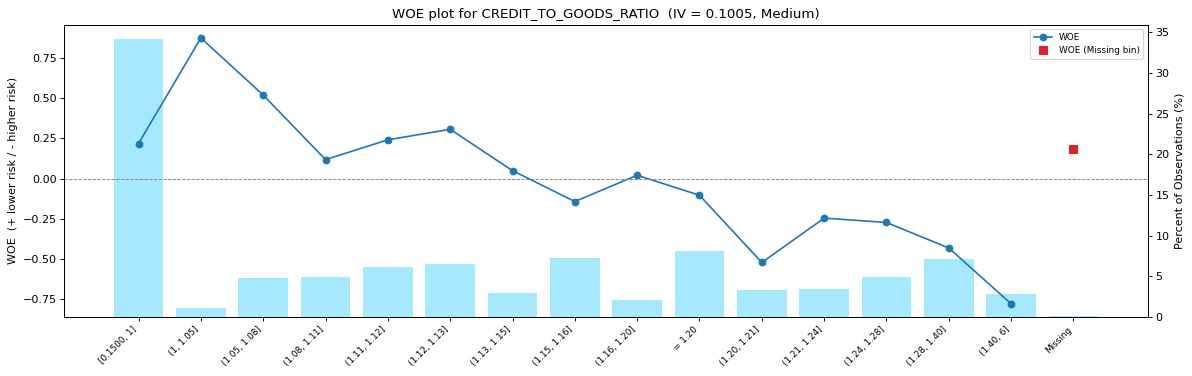

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
"[0.1500, 1]","51,075",34.21%,"3,323",6.51%,+0.2176,0.0148
"(1, 1.05]","1,664",1.11%,58,3.49%,+0.8735,0.0059
"(1.05, 1.08]","7,230",4.84%,354,4.90%,+0.5189,0.0105
"(1.08, 1.11]","7,408",4.96%,529,7.14%,+0.1177,0.0007
"(1.11, 1.12]","9,170",6.14%,584,6.37%,+0.2404,0.0032
"(1.12, 1.13]","9,734",6.52%,583,5.99%,+0.3058,0.0054
"(1.13, 1.15]","4,415",2.96%,336,7.61%,+0.0489,0.0001
"(1.15, 1.16]","10,900",7.30%,989,9.07%,-0.1429,0.0016
"(1.16, 1.20]","3,072",2.06%,240,7.81%,+0.0205,0.0000
= 1.20,"12,137",8.13%,"1,063",8.76%,-0.1041,0.0009


#### 4. ACTIVE_LOAN_RATIO  
IV = 0.0964, Weak | 17 bins | WOE trend: Mostly monotonic (rho -0.94): risk rises as value rises

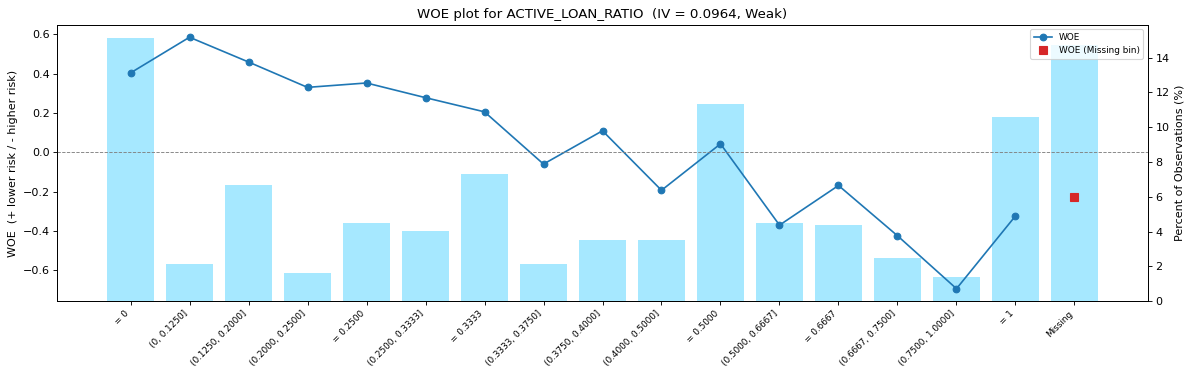

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
= 0,"22,605",15.14%,"1,234",5.46%,+0.4042,0.0209
"(0, 0.1250]","3,221",2.16%,148,4.59%,+0.5856,0.0058
"(0.1250, 0.2000]","9,963",6.67%,516,5.18%,+0.4598,0.0116
"(0.2000, 0.2500]","2,393",1.60%,140,5.85%,+0.3308,0.0015
= 0.2500,"6,738",4.51%,386,5.73%,+0.3531,0.0049
"(0.2500, 0.3333]","5,988",4.01%,368,6.15%,+0.2784,0.0028
= 0.3333,"10,936",7.32%,719,6.57%,+0.2064,0.0029
"(0.3333, 0.3750]","3,224",2.16%,271,8.41%,-0.0591,0.0001
"(0.3750, 0.4000]","5,243",3.51%,377,7.19%,+0.1102,0.0004
"(0.4000, 0.5000]","5,216",3.49%,495,9.49%,-0.1924,0.0014


#### 5. MOST_RECENT_CREDIT_AGE  
IV = 0.0932, Weak | 21 bins | WOE trend: Mostly monotonic (rho +0.93): risk falls as value rises

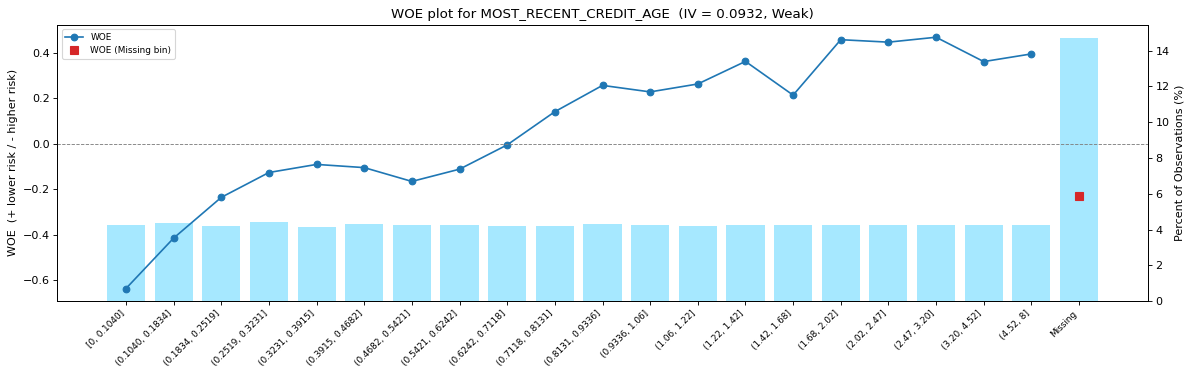

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
"[0, 0.1040]","6,368",4.26%,895,14.05%,-0.6368,0.0226
"(0.1040, 0.1834]","6,519",4.37%,755,11.58%,-0.4149,0.0089
"(0.1834, 0.2519]","6,263",4.19%,618,9.87%,-0.2355,0.0026
"(0.2519, 0.3231]","6,580",4.41%,588,8.94%,-0.1261,0.0007
"(0.3231, 0.3915]","6,219",4.16%,538,8.65%,-0.0906,0.0004
"(0.3915, 0.4682]","6,425",4.30%,563,8.76%,-0.1046,0.0005
"(0.4682, 0.5421]","6,360",4.26%,589,9.26%,-0.1654,0.0012
"(0.5421, 0.6242]","6,351",4.25%,560,8.82%,-0.1115,0.0006
"(0.6242, 0.7118]","6,304",4.22%,504,7.99%,-0.0045,0.0000
"(0.7118, 0.8131]","6,300",4.22%,440,6.98%,+0.1415,0.0008


#### 6. OCCUPATION_TYPE  
IV = 0.0849, Weak | 19 bins | WOE trend: Categories: highest risk "Low-skill Laborers", lowest risk "Accountants"

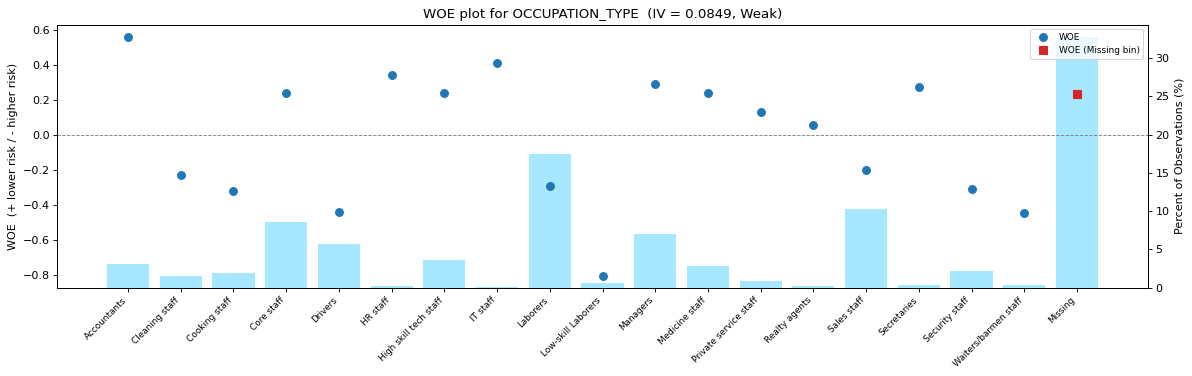

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
Accountants,"4,624",3.10%,217,4.69%,+0.5635,0.0078
Cleaning staff,"2,335",1.56%,229,9.81%,-0.2288,0.0009
Cooking staff,"2,905",1.95%,309,10.64%,-0.3192,0.0023
Core staff,"12,896",8.64%,819,6.35%,+0.2434,0.0046
Drivers,"8,522",5.71%,"1,009",11.84%,-0.4399,0.0133
HR staff,259,0.17%,15,5.79%,+0.3415,0.0002
High skill tech staff,"5,468",3.66%,349,6.38%,+0.2381,0.0019
IT staff,203,0.14%,11,5.42%,+0.4120,0.0002
Laborers,"26,145",17.51%,"2,706",10.35%,-0.2887,0.0165
Low-skill Laborers,975,0.65%,158,16.21%,-0.8045,0.0059


#### 7. OLDEST_CREDIT_AGE  
IV = 0.0803, Weak | 21 bins | WOE trend: Mostly monotonic (rho +0.97): risk falls as value rises

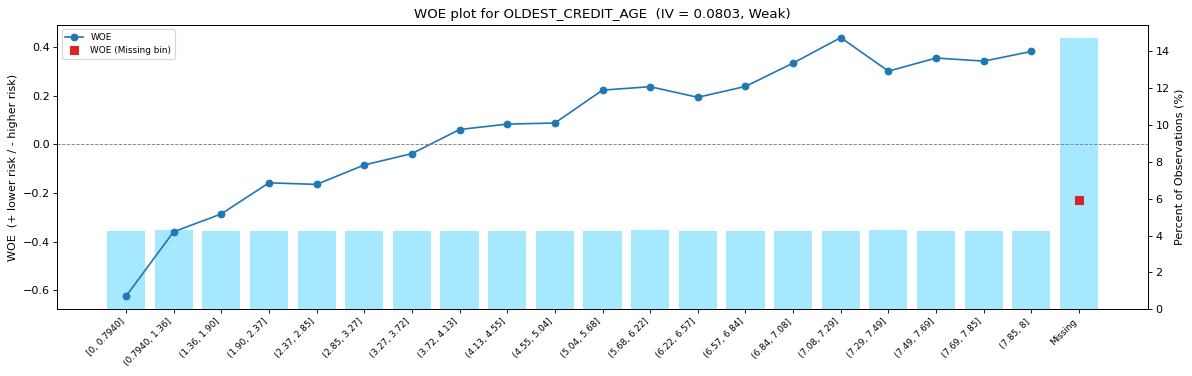

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
"[0, 0.7940]","6,380",4.27%,887,13.90%,-0.6242,0.0216
"(0.7940, 1.36]","6,388",4.28%,704,11.02%,-0.3590,0.0064
"(1.36, 1.90]","6,355",4.26%,656,10.32%,-0.2857,0.0039
"(1.90, 2.37]","6,372",4.27%,586,9.20%,-0.1577,0.0011
"(2.37, 2.85]","6,367",4.26%,589,9.25%,-0.1642,0.0012
"(2.85, 3.27]","6,359",4.26%,547,8.60%,-0.0844,0.0003
"(3.27, 3.72]","6,370",4.27%,525,8.24%,-0.0376,0.0001
"(3.72, 4.13]","6,354",4.26%,478,7.52%,+0.0614,0.0002
"(4.13, 4.55]","6,364",4.26%,469,7.37%,+0.0837,0.0003
"(4.55, 5.04]","6,377",4.27%,468,7.34%,+0.0882,0.0003


#### 8. ACTIVE_LOAN_COUNT  
IV = 0.0634, Weak | 8 bins | WOE trend: Monotonic: risk rises as value rises

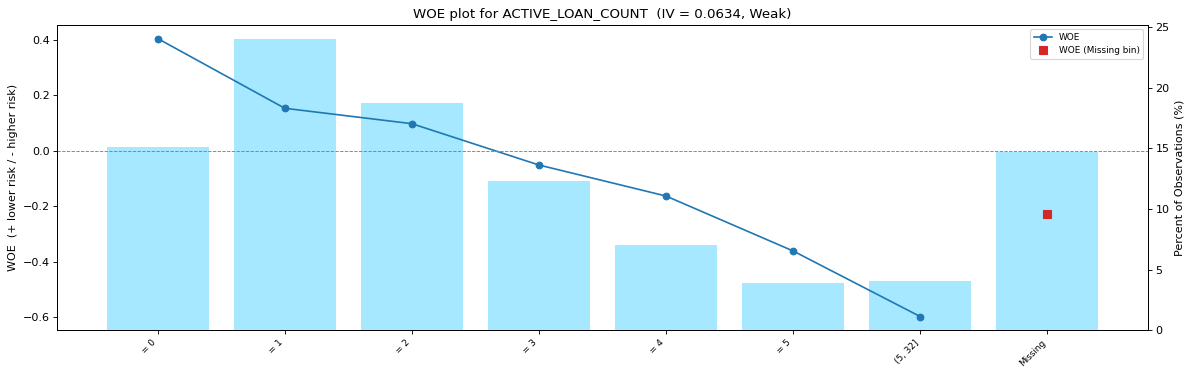

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
= 0,"22,605",15.14%,"1,234",5.46%,+0.4042,0.0209
= 1,"35,846",24.01%,"2,477",6.91%,+0.1530,0.0053
= 2,"27,996",18.75%,"2,037",7.28%,+0.0975,0.0017
= 3,"18,402",12.32%,"1,536",8.35%,-0.0515,0.0003
= 4,"10,505",7.04%,971,9.24%,-0.1633,0.0020
= 5,"5,859",3.92%,647,11.04%,-0.3612,0.0060
"(5, 32]","6,124",4.10%,832,13.59%,-0.5975,0.0188
Missing,"21,981",14.72%,"2,154",9.80%,-0.2279,0.0084


#### 9. NAME_INCOME_TYPE  
IV = 0.0622, Weak | 8 bins | WOE trend: Categories: highest risk "Maternity leave", lowest risk "Pensioner"

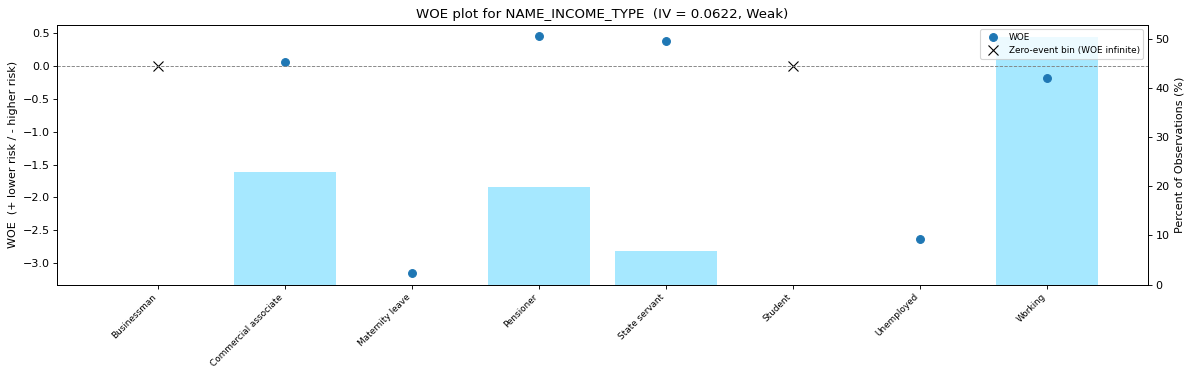

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
Businessman,5,0.00%,0,0.00%,inf (zero-event),inf (zero-event)
Commercial associate,"34,357",23.01%,"2,607",7.59%,+0.0521,0.0006
Maternity leave,3,0.00%,2,66.67%,-3.1407,0.0005
Pensioner,"29,556",19.79%,"1,559",5.27%,+0.4405,0.0320
State servant,"10,082",6.75%,571,5.66%,+0.3652,0.0077
Student,9,0.01%,0,0.00%,inf (zero-event),inf (zero-event)
Unemployed,11,0.01%,6,54.55%,-2.6299,0.0012
Working,"75,295",50.43%,"7,143",9.49%,-0.1920,0.0201


#### 10. DEBT_TO_CREDIT_RATIO  
IV = 0.0619, Weak | 20 bins | WOE trend: Mostly monotonic (rho -0.95): risk rises as value rises

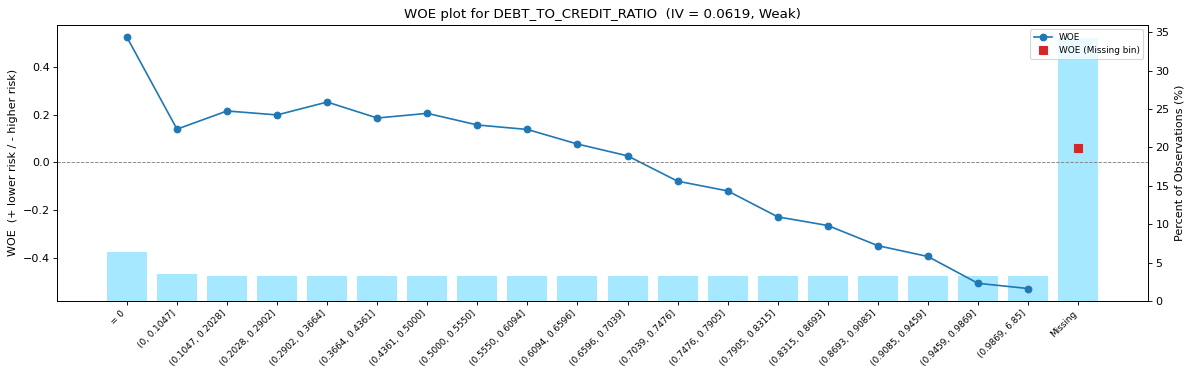

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
= 0,"9,480",6.35%,462,4.87%,+0.5238,0.0140
"(0, 0.1047]","5,242",3.51%,367,7.00%,+0.1389,0.0006
"(0.1047, 0.2028]","4,907",3.29%,320,6.52%,+0.2151,0.0014
"(0.2028, 0.2902]","4,907",3.29%,325,6.62%,+0.1985,0.0012
"(0.2902, 0.3664]","4,907",3.29%,309,6.30%,+0.2525,0.0019
"(0.3664, 0.4361]","4,908",3.29%,329,6.70%,+0.1856,0.0010
"(0.4361, 0.5000]","4,907",3.29%,323,6.58%,+0.2051,0.0013
"(0.5000, 0.5550]","4,907",3.29%,338,6.89%,+0.1564,0.0008
"(0.5550, 0.6094]","4,907",3.29%,344,7.01%,+0.1375,0.0006
"(0.6094, 0.6596]","4,907",3.29%,364,7.42%,+0.0766,0.0002


#### 11. AMT_CREDIT  
IV = 0.0570, Weak | 20 bins | WOE trend: Non-monotonic (rho +0.27)

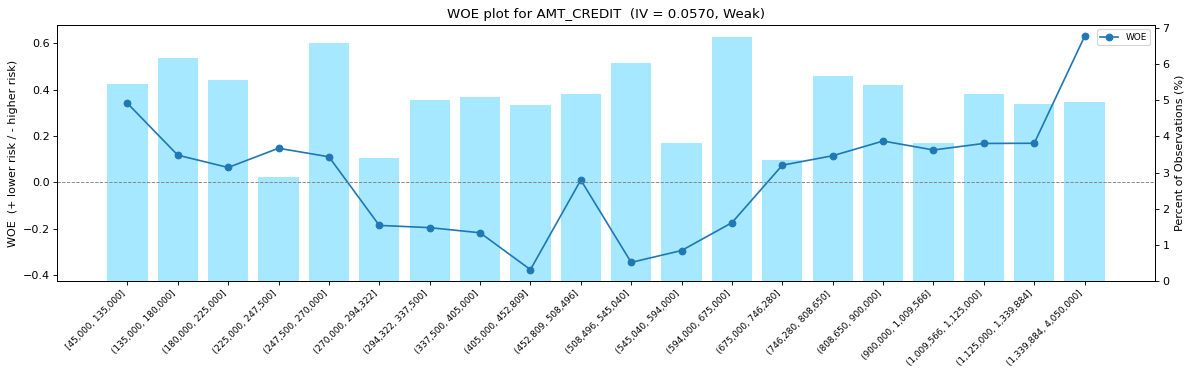

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
"[45,000, 135,000]","8,128",5.44%,471,5.79%,+0.3409,0.0055
"(135,000, 180,000]","9,198",6.16%,657,7.14%,+0.1174,0.0008
"(180,000, 225,000]","8,290",5.55%,622,7.50%,+0.0643,0.0002
"(225,000, 247,500]","4,318",2.89%,300,6.95%,+0.1472,0.0006
"(247,500, 270,000]","9,820",6.58%,706,7.19%,+0.1104,0.0008
"(270,000, 294,322]","5,091",3.41%,480,9.43%,-0.1852,0.0013
"(294,322, 337,500]","7,486",5.01%,712,9.51%,-0.1948,0.0021
"(337,500, 405,000]","7,585",5.08%,736,9.70%,-0.2170,0.0026
"(405,000, 452,809]","7,277",4.87%,814,11.19%,-0.3757,0.0081
"(452,809, 508,496]","7,709",5.16%,608,7.89%,+0.0102,0.0000


#### 12. EXISTING_DEBT_SHARE_OF_EXPOSURE  
IV = 0.0515, Weak | 17 bins | WOE trend: Weak trend (rho -0.76): risk rises as value rises

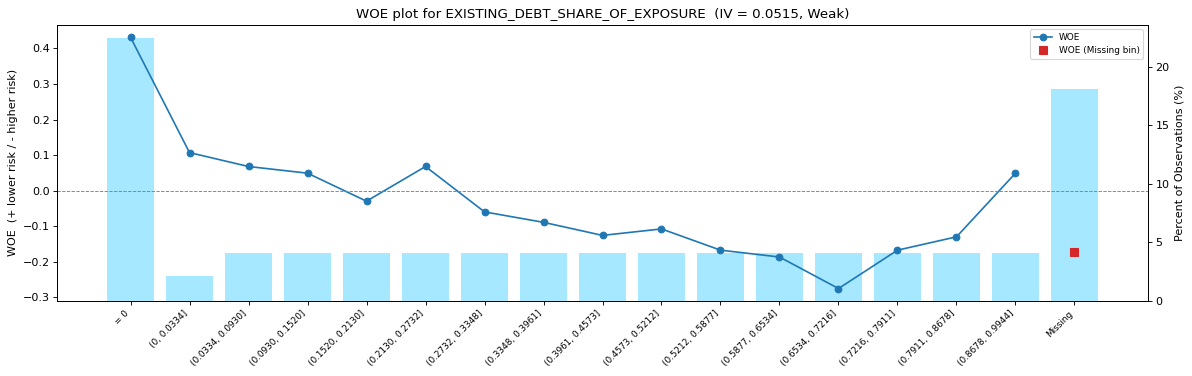

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
= 0,"33,539",22.46%,"1,784",5.32%,+0.4316,0.0350
"(0, 0.0334]","3,134",2.10%,226,7.21%,+0.1071,0.0002
"(0.0334, 0.0930]","6,112",4.09%,457,7.48%,+0.0680,0.0002
"(0.0930, 0.1520]","6,112",4.09%,465,7.61%,+0.0493,0.0001
"(0.1520, 0.2130]","6,112",4.09%,500,8.18%,-0.0295,0.0000
"(0.2130, 0.2732]","6,112",4.09%,457,7.48%,+0.0680,0.0002
"(0.2732, 0.3348]","6,112",4.09%,514,8.41%,-0.0596,0.0001
"(0.3348, 0.3961]","6,112",4.09%,528,8.64%,-0.0890,0.0003
"(0.3961, 0.4573]","6,112",4.09%,546,8.93%,-0.1258,0.0007
"(0.4573, 0.5212]","6,112",4.09%,537,8.79%,-0.1075,0.0005


#### 13. BUREAU_DEBT_TO_INCOME  
IV = 0.0497, Weak | 17 bins | WOE trend: Mostly monotonic (rho -0.92): risk rises as value rises

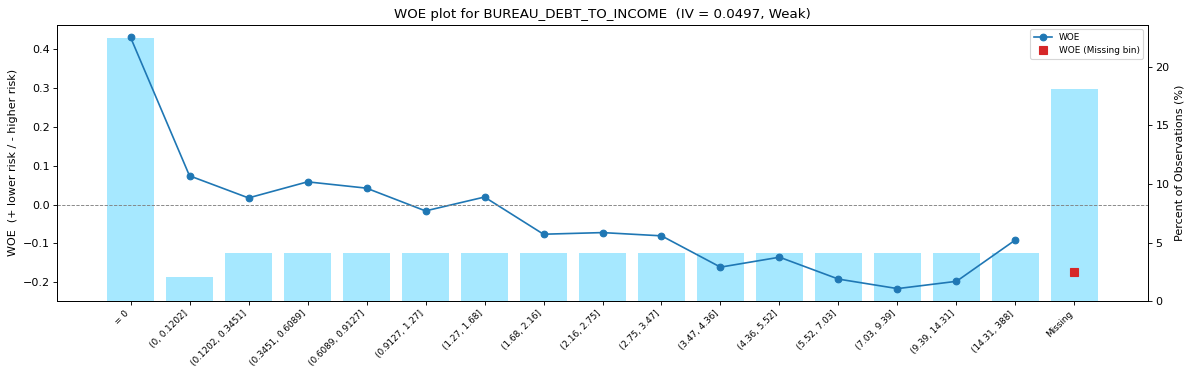

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
= 0,"33,539",22.46%,"1,784",5.32%,+0.4316,0.0350
"(0, 0.1202]","3,134",2.10%,233,7.43%,+0.0742,0.0001
"(0.1202, 0.3451]","6,112",4.09%,479,7.84%,+0.0171,0.0000
"(0.3451, 0.6089]","6,112",4.09%,461,7.54%,+0.0586,0.0001
"(0.6089, 0.9127]","6,112",4.09%,468,7.66%,+0.0423,0.0001
"(0.9127, 1.27]","6,112",4.09%,494,8.08%,-0.0164,0.0000
"(1.27, 1.68]","6,112",4.09%,478,7.82%,+0.0194,0.0000
"(1.68, 2.16]","6,112",4.09%,522,8.54%,-0.0765,0.0002
"(2.16, 2.75]","6,112",4.09%,520,8.51%,-0.0723,0.0002
"(2.75, 3.47]","6,112",4.09%,524,8.57%,-0.0807,0.0003


#### 14. NAME_EDUCATION_TYPE  
IV = 0.0467, Weak | 5 bins | WOE trend: Categories: highest risk "Lower secondary", lowest risk "Academic degree"

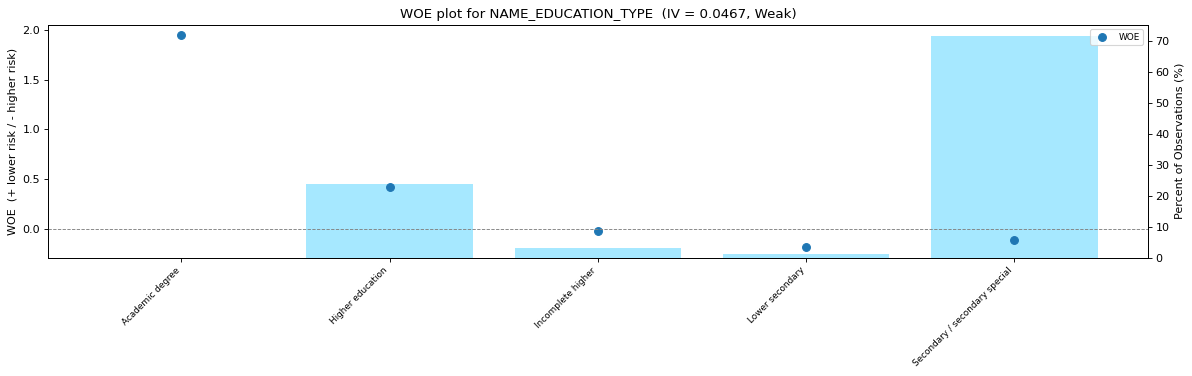

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
Academic degree,82,0.05%,1,1.22%,+1.9469,0.0010
Higher education,"35,843",24.00%,"1,920",5.36%,+0.4242,0.0362
Incomplete higher,"4,580",3.07%,373,8.14%,-0.0247,0.0000
Lower secondary,"1,760",1.18%,166,9.43%,-0.1856,0.0004
Secondary / secondary special,"107,053",71.69%,"9,428",8.81%,-0.1101,0.0091


#### 15. ACTIVE_CREDIT_CARD_COUNT  
IV = 0.0427, Weak | 6 bins | WOE trend: Monotonic: risk rises as value rises

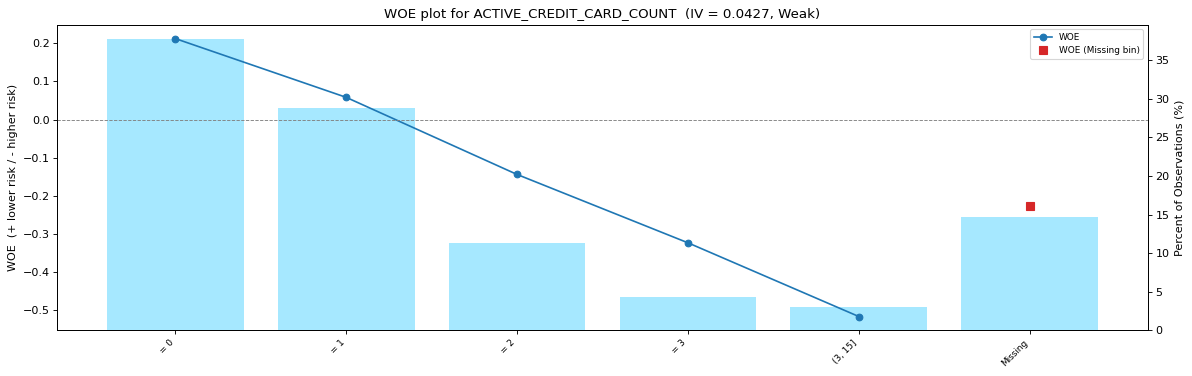

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
= 0,"56,299",37.70%,"3,680",6.54%,+0.2126,0.0156
= 1,"43,081",28.85%,"3,250",7.54%,+0.0584,0.0010
= 2,"16,924",11.33%,"1,537",9.08%,-0.1439,0.0025
= 3,"6,548",4.39%,699,10.68%,-0.3232,0.0052
"(3, 15]","4,485",3.00%,568,12.66%,-0.5166,0.0100
Missing,"21,981",14.72%,"2,154",9.80%,-0.2279,0.0084


#### 16. FLAG_DAYS_EMPLOYED_SPECIAL  
IV = 0.0377, Weak | 2 bins | WOE trend: Categories: highest risk "0", lowest risk "1"

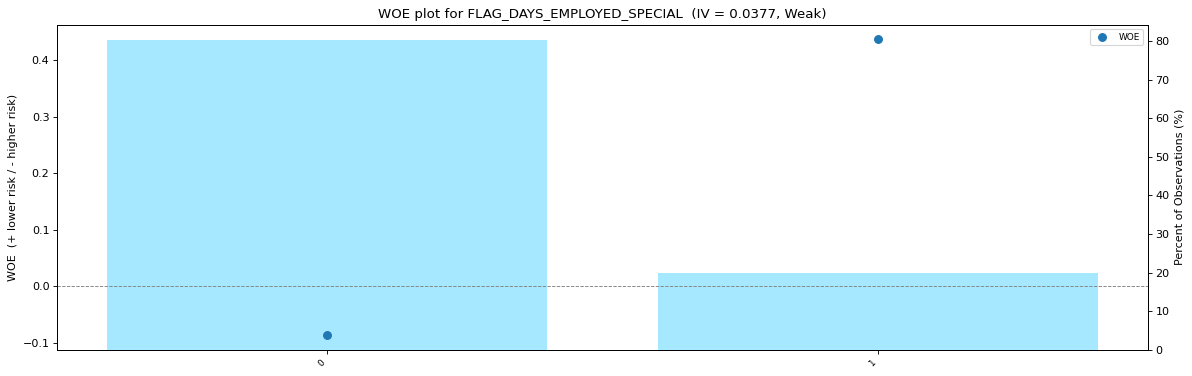

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
0,"119,755",80.20%,"10,323",8.62%,-0.0867,0.0062
1,"29,563",19.80%,"1,565",5.29%,+0.4367,0.0315


#### 17. MICROLOAN_COUNT  
IV = 0.0284, Weak | 3 bins | WOE trend: Monotonic: risk rises as value rises

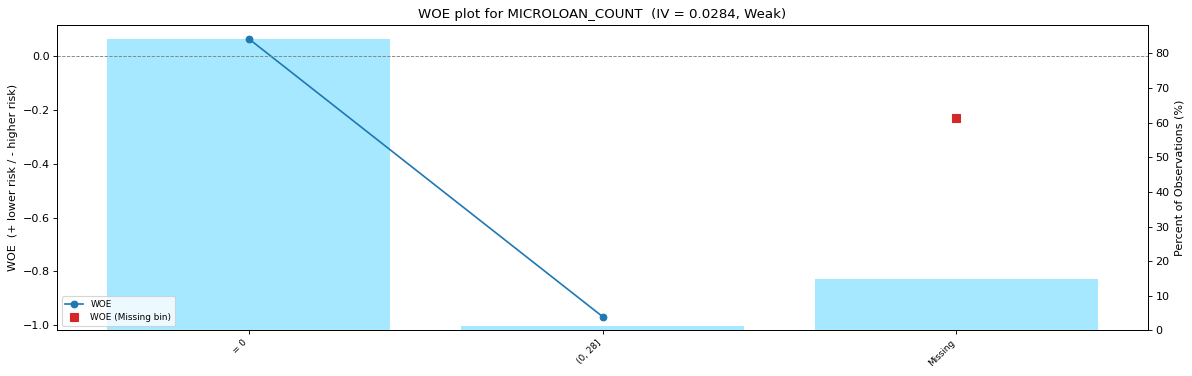

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
= 0,"125,585",84.11%,"9,409",7.49%,+0.0659,0.0035
"(0, 28]","1,752",1.17%,325,18.55%,-0.9681,0.0164
Missing,"21,981",14.72%,"2,154",9.80%,-0.2279,0.0084


#### 18. OVERDUE_LOAN_COUNT  
IV = 0.0188, No predictive power | 3 bins | WOE trend: Monotonic: risk rises as value rises

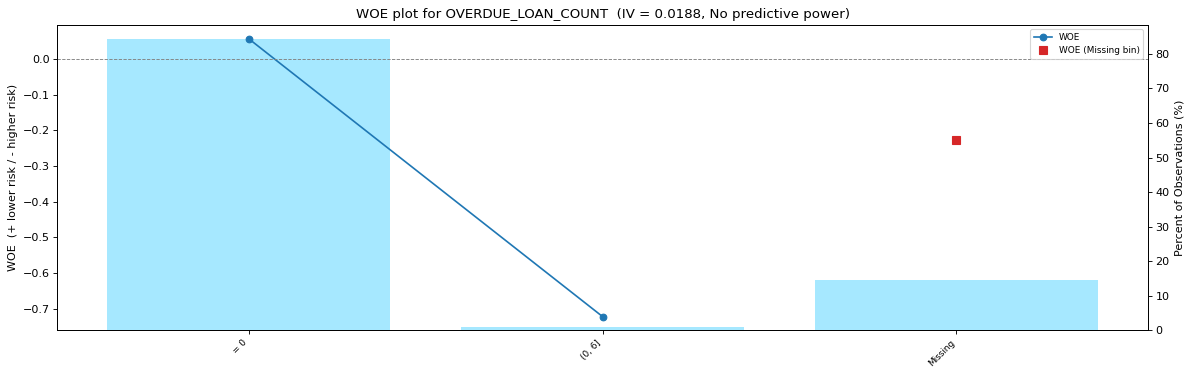

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
= 0,"125,723",84.20%,"9,490",7.55%,+0.0578,0.0027
"(0, 6]","1,614",1.08%,244,15.12%,-0.7222,0.0076
Missing,"21,981",14.72%,"2,154",9.80%,-0.2279,0.0084


#### 19. MORTGAGE_COUNT  
IV = 0.0176, No predictive power | 3 bins | WOE trend: Monotonic: risk falls as value rises

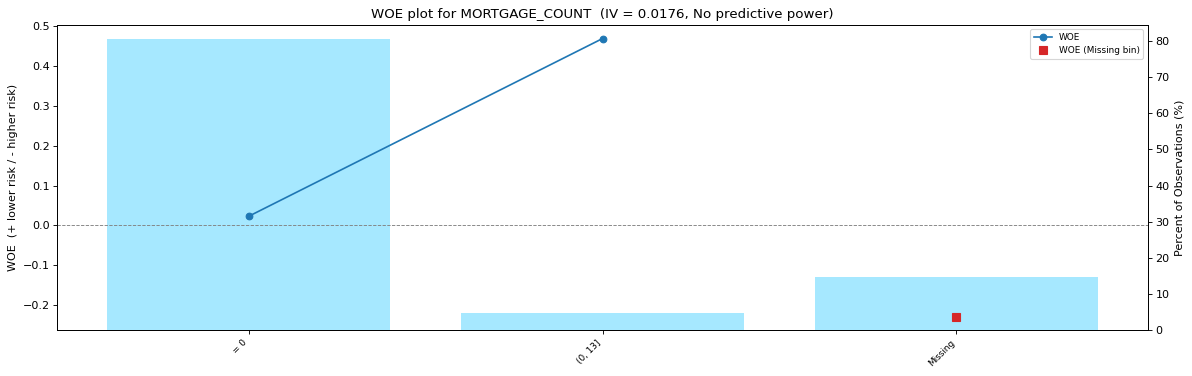

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
= 0,"120,042",80.39%,"9,359",7.80%,+0.0227,0.0004
"(0, 13]","7,295",4.89%,375,5.14%,+0.4677,0.0088
Missing,"21,981",14.72%,"2,154",9.80%,-0.2279,0.0084


#### 20. NAME_CONTRACT_TYPE  
IV = 0.0164, No predictive power | 2 bins | WOE trend: Categories: highest risk "Cash loans", lowest risk "Revolving loans"

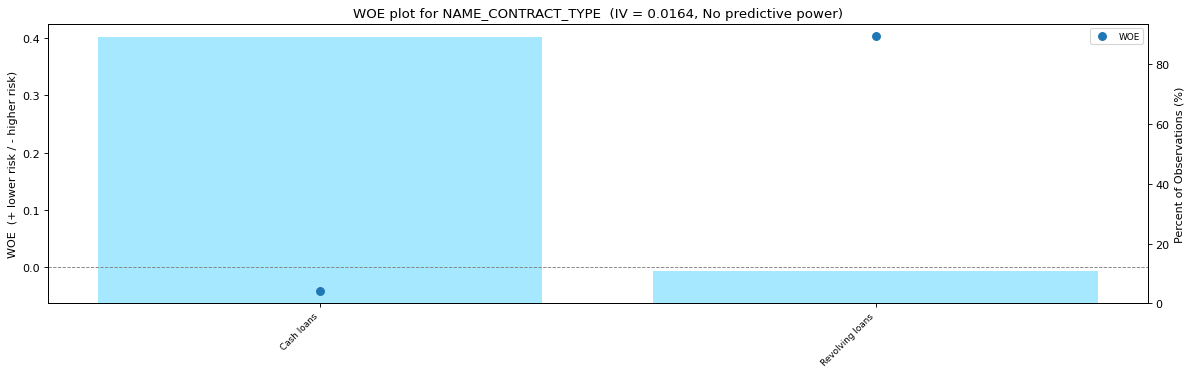

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
Cash loans,"133,094",89.13%,"11,001",8.27%,-0.0408,0.0015
Revolving loans,"16,224",10.87%,887,5.47%,+0.4026,0.0149


#### 21. BUREAU_LOAN_COUNT  
IV = 0.0149, No predictive power | 14 bins | WOE trend: Non-monotonic (rho -0.24)

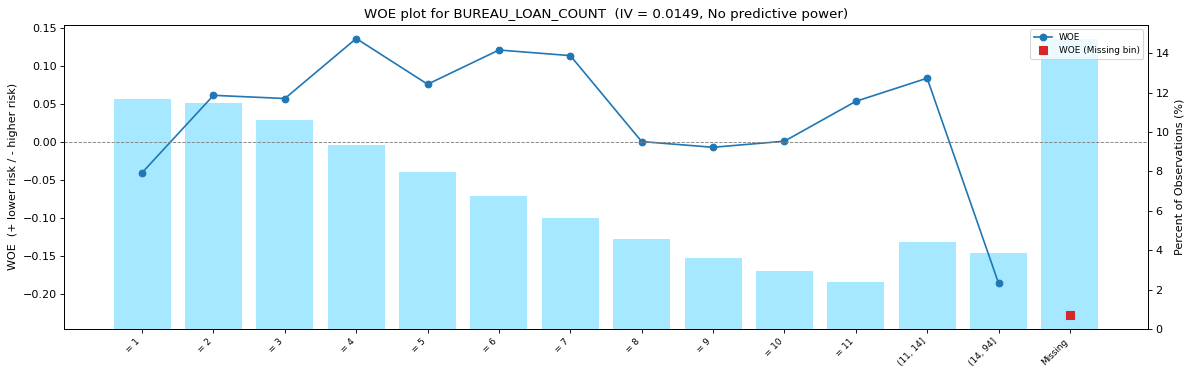

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
= 1,"17,433",11.68%,"1,440",8.26%,-0.0401,0.0002
= 2,"17,141",11.48%,"1,289",7.52%,+0.0618,0.0004
= 3,"15,856",10.62%,"1,197",7.55%,+0.0577,0.0003
= 4,"13,969",9.36%,980,7.02%,+0.1367,0.0017
= 5,"11,902",7.97%,883,7.42%,+0.0765,0.0005
= 6,"10,063",6.74%,716,7.12%,+0.1215,0.0009
= 7,"8,417",5.64%,603,7.16%,+0.1142,0.0007
= 8,"6,851",4.59%,545,7.96%,+0.0009,0.0000
= 9,"5,418",3.63%,434,8.01%,-0.0066,0.0000
= 10,"4,364",2.92%,347,7.95%,+0.0014,0.0000


#### 22. TOTAL_BUREAU_ENQUIRIES_12M  
IV = 0.0148, No predictive power | 10 bins | WOE trend: Mostly monotonic (rho -0.93): risk rises as value rises

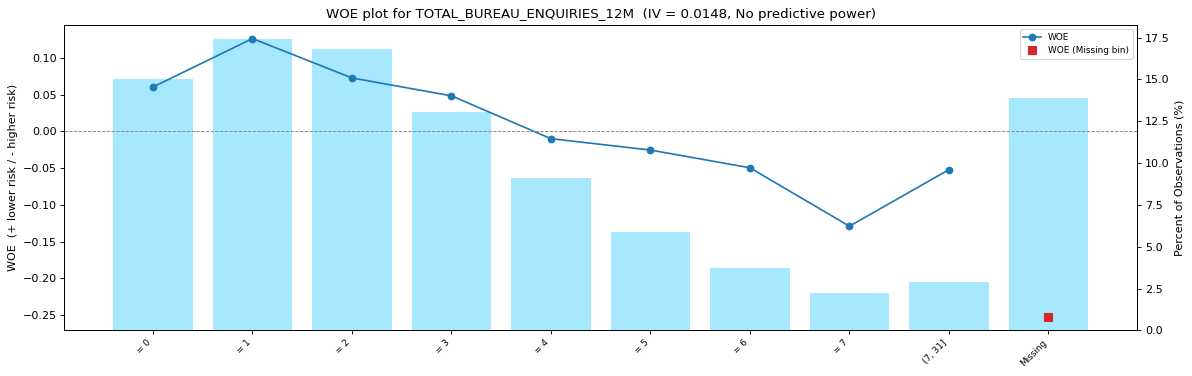

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
= 0,"22,470",15.05%,"1,692",7.53%,+0.0604,0.0005
= 1,"25,991",17.41%,"1,841",7.08%,+0.1264,0.0026
= 2,"25,094",16.81%,"1,868",7.44%,+0.0728,0.0009
= 3,"19,465",13.04%,"1,482",7.61%,+0.0484,0.0003
= 4,"13,592",9.10%,"1,092",8.03%,-0.0099,0.0000
= 5,"8,774",5.88%,715,8.15%,-0.0253,0.0000
= 6,"5,533",3.71%,461,8.33%,-0.0495,0.0001
= 7,"3,315",2.22%,297,8.96%,-0.1290,0.0004
"(7, 31]","4,323",2.90%,361,8.35%,-0.0520,0.0001
Missing,"20,761",13.90%,"2,079",10.01%,-0.2519,0.0098


#### 23. ADVERSE_STATUS_COUNT  
IV = 0.0120, No predictive power | 3 bins | WOE trend: Monotonic: risk rises as value rises

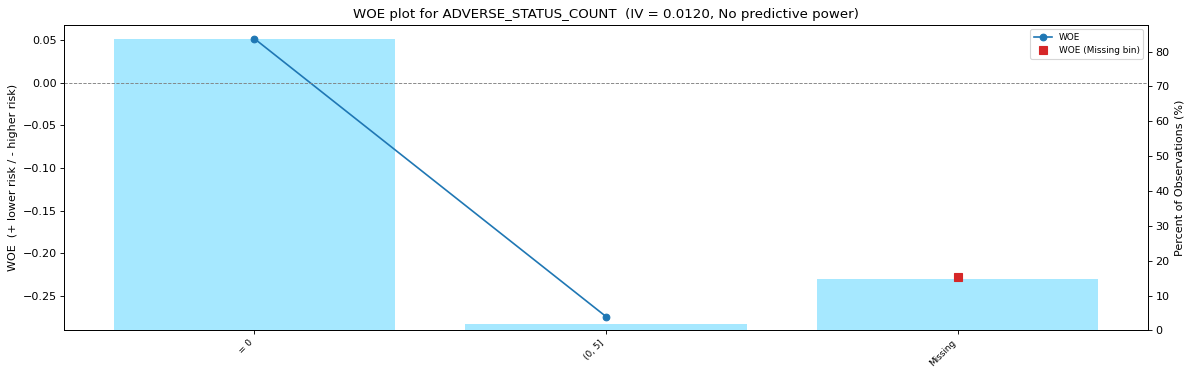

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
= 0,"124,762",83.55%,"9,471",7.59%,+0.0516,0.0022
"(0, 5]","2,575",1.72%,263,10.21%,-0.2739,0.0015
Missing,"21,981",14.72%,"2,154",9.80%,-0.2279,0.0084


#### 24. LOAN_TO_INCOME  
IV = 0.0113, No predictive power | 20 bins | WOE trend: Non-monotonic (rho +0.02)

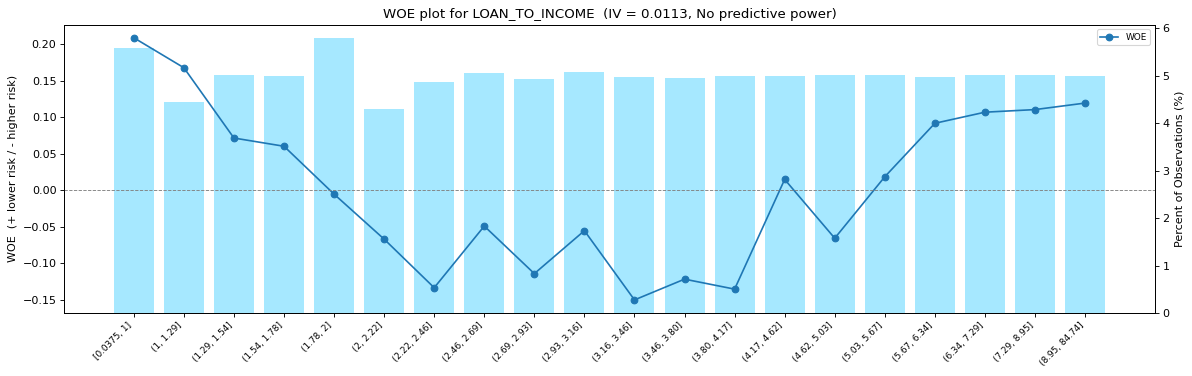

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
"[0.0375, 1]","8,342",5.59%,547,6.56%,+0.2092,0.0022
"(1, 1.29]","6,634",4.44%,452,6.81%,+0.1681,0.0012
"(1.29, 1.54]","7,502",5.02%,559,7.45%,+0.0718,0.0003
"(1.54, 1.78]","7,464",5.00%,562,7.53%,+0.0605,0.0002
"(1.78, 2]","8,638",5.78%,691,8.00%,-0.0052,0.0000
"(2, 2.22]","6,426",4.30%,544,8.47%,-0.0669,0.0002
"(2.22, 2.46]","7,281",4.88%,655,9.00%,-0.1335,0.0009
"(2.46, 2.69]","7,541",5.05%,628,8.33%,-0.0490,0.0001
"(2.69, 2.93]","7,365",4.93%,651,8.84%,-0.1141,0.0007
"(2.93, 3.16]","7,593",5.09%,636,8.38%,-0.0553,0.0002


#### 25. AMT_INCOME_TOTAL  
IV = 0.0106, No predictive power | 20 bins | WOE trend: Non-monotonic (rho +0.36)

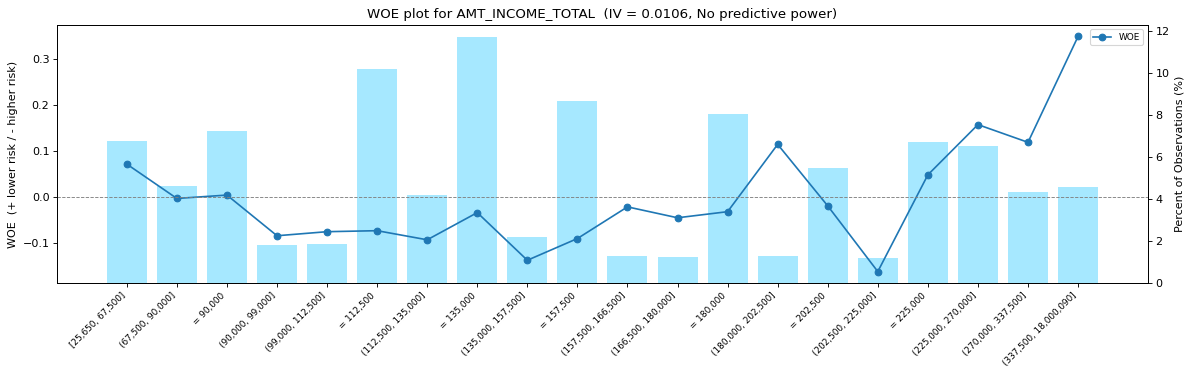

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
"[25,650, 67,500]","10,068",6.74%,751,7.46%,+0.0706,0.0003
"(67,500, 90,000]","6,882",4.61%,550,7.99%,-0.0041,0.0000
"= 90,000","10,834",7.26%,860,7.94%,+0.0032,0.0000
"(90,000, 99,000]","2,718",1.82%,234,8.61%,-0.0853,0.0001
"(99,000, 112,500]","2,822",1.89%,241,8.54%,-0.0764,0.0001
"= 112,500","15,194",10.18%,"1,295",8.52%,-0.0743,0.0006
"(112,500, 135,000]","6,268",4.20%,544,8.68%,-0.0941,0.0004
"= 135,000","17,479",11.71%,"1,437",8.22%,-0.0349,0.0001
"(135,000, 157,500]","3,297",2.21%,298,9.04%,-0.1386,0.0004
"= 157,500","12,937",8.66%,"1,120",8.66%,-0.0914,0.0008


#### 26. TOTAL_PROLONGATIONS  
IV = 0.0104, No predictive power | 3 bins | WOE trend: Monotonic: risk rises as value rises

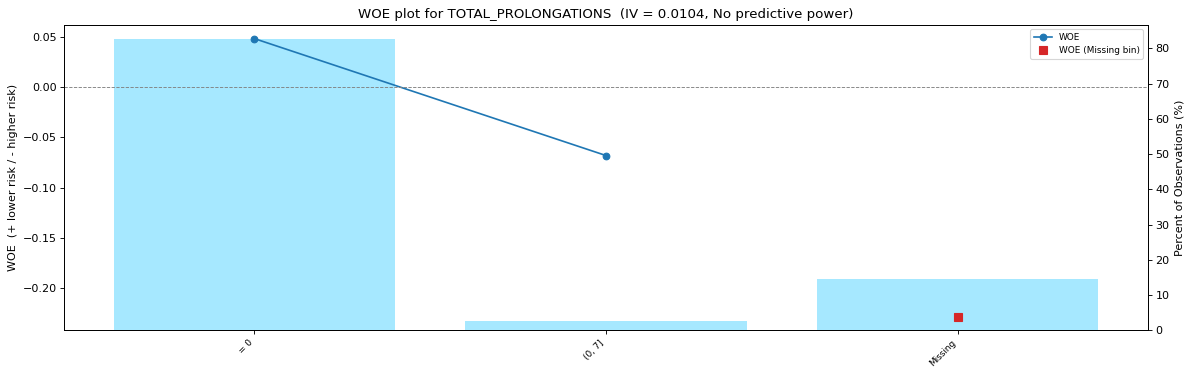

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
= 0,"123,278",82.56%,"9,390",7.62%,+0.0480,0.0019
"(0, 7]","4,059",2.72%,344,8.47%,-0.0681,0.0001
Missing,"21,981",14.72%,"2,154",9.80%,-0.2279,0.0084


#### 27. HAS_BUREAU_HISTORY  
IV = 0.0100, No predictive power | 2 bins | WOE trend: Categories: highest risk "0", lowest risk "1"

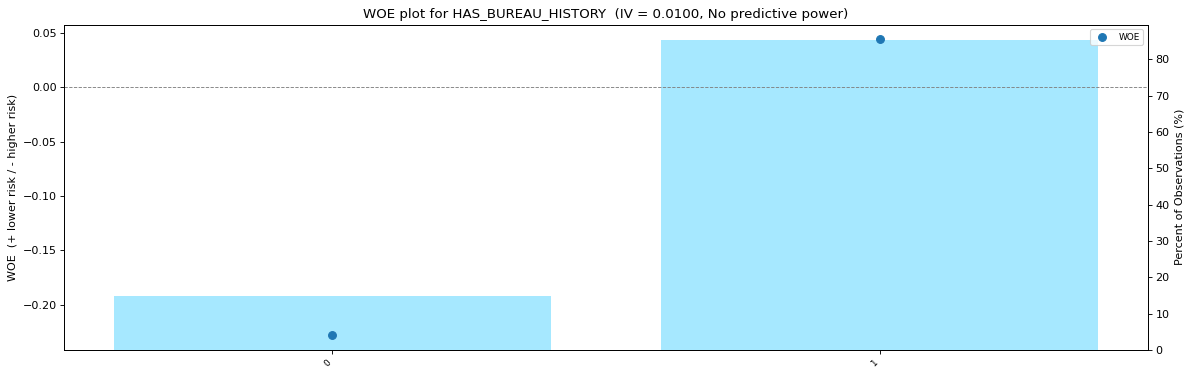

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
0,"21,981",14.72%,"2,154",9.80%,-0.2279,0.0084
1,"127,337",85.28%,"9,734",7.64%,+0.0441,0.0016


#### 28. NAME_HOUSING_TYPE  
IV = 0.0083, No predictive power | 6 bins | WOE trend: Categories: highest risk "With parents", lowest risk "House / apartment"

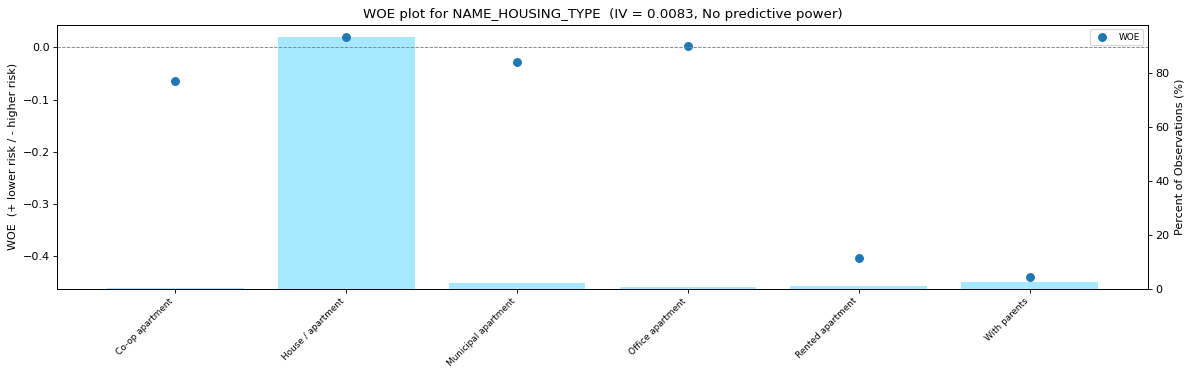

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
Co-op apartment,497,0.33%,42,8.45%,-0.0650,0.0000
House / apartment,"139,472",93.41%,"10,894",7.81%,+0.0207,0.0004
Municipal apartment,"3,025",2.03%,247,8.17%,-0.0275,0.0000
Office apartment,969,0.65%,77,7.95%,+0.0021,0.0000
Rented apartment,"1,458",0.98%,167,11.45%,-0.4024,0.0019
With parents,"3,897",2.61%,461,11.83%,-0.4389,0.0060


#### 29. ANNUITY_TO_INCOME  
IV = 0.0067, No predictive power | 21 bins | WOE trend: Weak trend (rho -0.69): risk rises as value rises

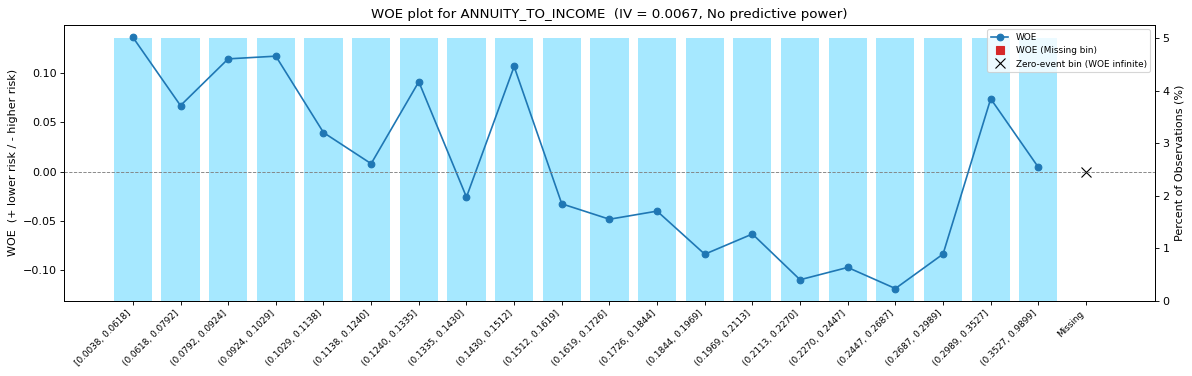

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
"[0.0038, 0.0618]","7,466",5.00%,524,7.02%,+0.1363,0.0009
"(0.0618, 0.0792]","7,469",5.00%,559,7.48%,+0.0670,0.0002
"(0.0792, 0.0924]","7,469",5.00%,535,7.16%,+0.1143,0.0006
"(0.0924, 0.1029]","7,460",5.00%,533,7.14%,+0.1171,0.0007
"(0.1029, 0.1138]","7,465",5.00%,573,7.68%,+0.0396,0.0001
"(0.1138, 0.1240]","7,466",5.00%,590,7.90%,+0.0081,0.0000
"(0.1240, 0.1335]","7,474",5.01%,547,7.32%,+0.0911,0.0004
"(0.1335, 0.1430]","7,458",4.99%,608,8.15%,-0.0258,0.0000
"(0.1430, 0.1512]","7,471",5.00%,539,7.21%,+0.1066,0.0005
"(0.1512, 0.1619]","7,460",5.00%,612,8.20%,-0.0326,0.0001


#### 30. FLAG_OWN_CAR  
IV = 0.0041, No predictive power | 2 bins | WOE trend: Categories: highest risk "N", lowest risk "Y"

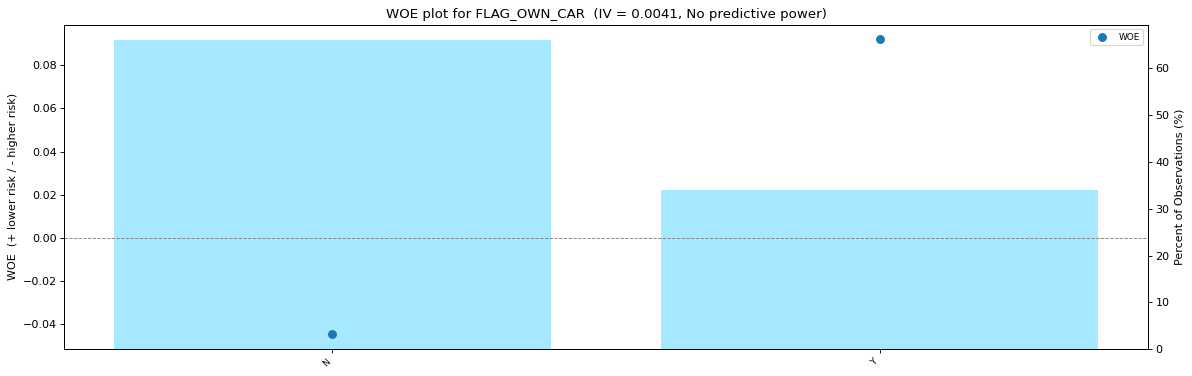

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
N,"98,587",66.02%,"8,178",8.30%,-0.0447,0.0013
Y,"50,731",33.98%,"3,710",7.31%,+0.0920,0.0028


In [16]:
for _, r in ranking.iterrows():
    variable = r['Characteristic']
    variable_data = fine_tables[variable]
    iv_text = 'IV not evaluable' if pd.isna(r['Fine IV']) else f"IV = {r['Fine IV']:.4f}, {r['Predictive strength']}"
    display(Markdown(f"#### {r['Rank']}. {variable}  \n{iv_text} | {r['Number of bins']} bins | WOE trend: {r['WOE trend']}"))
    woe_iv_plot(variable_data, variable, iv_text, r['Type'] == 'Categorical')
    display(variable_data[['Bin_Range', 'Count', '%_of_Obs', 'Events', 'Bad_Rate', 'WOE', 'IV']]
            .style.format({'Count': '{:,}', '%_of_Obs': '{:.2%}', 'Events': '{:,}', 'Bad_Rate': '{:.2%}',
                           'WOE': '{:+.4f}', 'IV': '{:.4f}'}, na_rep='inf (zero-event)').hide(axis='index'))

## 5.6B Which Characteristics to Keep or Drop

We give each characteristic a **first-pass** decision. The IV class is where we start, but we do not apply it mechanically: we also weigh business relevance, WOE shape, missingness and overlap with other characteristics. **We only remove a characteristic once the team agrees.**

| Category | Meaning |
|---|---|
| **PRIORITISE RETAINING** | Medium or strong IV, a WOE pattern that makes sense, clear business relevance, no open concerns |
| **CONSIDER RETAINING** | Weak IV, but useful business information that may add to the others |
| **PROPOSE DROPPING** | No real predictive power, or weak without a strong business reason, or redundant |
| **INVESTIGATE** | IV above 0.50, unstable WOE, small or zero-event bins, possible leakage, or high missingness that needs a decision |

In [17]:
recommendation_table = ranking[['Rank', 'Characteristic', 'Fine IV', 'Predictive strength']].copy()
recommendation_table['Recommendation'] = recommendation_table['Characteristic'].map(lambda c: RECOMMENDATIONS[c][0])
recommendation_table['Justification'] = recommendation_table['Characteristic'].map(lambda c: RECOMMENDATIONS[c][1])
recommendation_table = recommendation_table.rename(columns={'Fine IV': 'IV', 'Predictive strength': 'Classification'})

assert set(RECOMMENDATIONS) == set(characteristics)
display(recommendation_table.set_index('Rank').style.format({'IV': '{:.4f}'}, na_rep='Not evaluable'))

rec_counts = recommendation_table['Recommendation'].value_counts().reindex(
    ['PRIORITISE RETAINING', 'CONSIDER RETAINING', 'PROPOSE DROPPING', 'INVESTIGATE'], fill_value=0)
display(rec_counts.to_frame('Characteristics'))
assert rec_counts.sum() == len(characteristics)

,Characteristic,IV,Classification,Recommendation,Justification
Rank,,,,,
1,CREDIT_TO_ANNUITY_RATIO,0.1664,Medium,INVESTIGATE,"Highest IV (medium), but the WOE zig-zags between neighbouring bins (2.1% vs 13.4% bad rate) and IV drops from 0.166 to 0.119 with 10 bins. The ratio is the implied repayment term, so it reflects product and pricing; if the lender priced by risk, part of its signal may be the lender's own risk view. Its only zero-event bin is the 2-applicant Missing bin. Needs a decision on whether to keep it and group it by product term"
2,EMPLOYMENT_YEARS,0.1185,Medium,PRIORITISE RETAINING,Medium IV with a near-monotonic trend (rho +0.94): risk falls steadily with years employed (10-12% bad rate under 3 years to 4.3% over 20 years). Its Missing bin is exactly the pensioner / no-employer group (low risk)
3,CREDIT_TO_GOODS_RATIO,0.1005,Medium,PRIORITISE RETAINING,"Medium IV with a clear trend: financing more than the goods price (insurance or fees added) raises risk, from 6.5% at a ratio of 1 or below to 15.9% above 1.40. Only 0.1% missing"
4,ACTIVE_LOAN_RATIO,0.0964,Weak,CONSIDER RETAINING,"Weak IV (0.096), just below medium, with a near-monotonic trend (rho -0.94): a higher share of credits still open means higher risk"
5,MOST_RECENT_CREDIT_AGE,0.0932,Weak,CONSIDER RETAINING,Weak IV (0.093) with a near-monotonic trend (rho +0.93): recent new credit means higher risk. Distinct from OLDEST_CREDIT_AGE (see rank correlation in 5.5)
6,OCCUPATION_TYPE,0.0849,Weak,CONSIDER RETAINING,"Weak IV (0.085), close to medium, with a clear spread (Accountants 4.7% to Low-skill Laborers 16.2%). 32.7% missing, but explained: 60% of the missing are pensioners and the rest did not state an occupation. Only 19% of its IV comes from the Missing bin. Small occupations need merging in coarse classing"
7,OLDEST_CREDIT_AGE,0.0803,Weak,CONSIDER RETAINING,Weak IV (0.080) with a near-monotonic trend (rho +0.97): a longer credit history means lower risk
8,ACTIVE_LOAN_COUNT,0.0634,Weak,CONSIDER RETAINING,Weak IV with a monotonic trend: risk rises with the number of active loans (5.5% with none to 13.6% with 6+). Rank-correlated 0.73 with ACTIVE_CREDIT_CARD_COUNT
9,NAME_INCOME_TYPE,0.0622,Weak,CONSIDER RETAINING,"Weak IV. Its strongest category (Pensioner) overlaps almost fully with the EMPLOYMENT_YEARS Missing bin, but it adds State servant (5.7% bad rate) vs Working (9.5%). Four tiny categories (28 applicants, two with zero bads) must be merged in coarse classing"


,Characteristics
Recommendation,
PRIORITISE RETAINING,2
CONSIDER RETAINING,13
PROPOSE DROPPING,14
INVESTIGATE,1


**What we recommend**

- **Our first pass:** 2 PRIORITISE RETAINING, 13 CONSIDER RETAINING, 1 INVESTIGATE, 14 PROPOSE DROPPING. If we accept every KEEP and INVESTIGATE item, **16 characteristics** go forward to coarse classing.
- **Not a mechanical IV cut-off:**
  - We keep `OVERDUE_LOAN_COUNT` (IV 0.0188, just below 0.02) for now, because it doubles the bad rate and is our only current-arrears measure.
  - We drop three weak-IV characteristics because stronger ones already carry their information: `FLAG_DAYS_EMPLOYED_SPECIAL`, `EXISTING_DEBT_SHARE_OF_EXPOSURE` and `NAME_CONTRACT_TYPE` (the last also has IV below 0.02).
- **Every risk area stays covered:**
  - affordability and loan: `CREDIT_TO_GOODS_RATIO`, `AMT_CREDIT`, `BUREAU_DEBT_TO_INCOME`, and possibly `CREDIT_TO_ANNUITY_RATIO`
  - job stability: `EMPLOYMENT_YEARS`, `NAME_INCOME_TYPE`, `OCCUPATION_TYPE`, `NAME_EDUCATION_TYPE`
  - existing credit exposure: `ACTIVE_LOAN_RATIO`, `ACTIVE_LOAN_COUNT`, `ACTIVE_CREDIT_CARD_COUNT`, `DEBT_TO_CREDIT_RATIO`, `MICROLOAN_COUNT`
  - arrears: `OVERDUE_LOAN_COUNT`
  - credit history: `OLDEST_CREDIT_AGE`, `MOST_RECENT_CREDIT_AGE`
- **What we had to decide as a team:**
  - **`CREDIT_TO_ANNUITY_RATIO`**: highest IV, but a zig-zag WOE, and possibly linked to the lender's pricing.
  - **Optional:** keep only one of `ACTIVE_LOAN_COUNT` / `ACTIVE_CREDIT_CARD_COUNT` (rank correlation 0.73).

## 5.6C Team Review: the Two Non-Monotonic Characteristics

**What we agreed after looking at the ranking (2026-10-30)**

- We carry `CREDIT_TO_ANNUITY_RATIO` forward, so our candidate list is 16; we decide whether it stays after coarse classing (5.8D).
- Coarse classing must make every WOE trend **monotonic**, as in the Week 10 lab.
- We aim for **around 12-15 characteristics**; any further removal needs its own reason.
- We look first at `CREDIT_TO_ANNUITY_RATIO` and `AMT_CREDIT`, whose WOE is not monotonic.

**Questions we investigated (training sample only)**

1. Is the zig-zag / hump real or just noise? We split the training sample into two random halves and compare the fine-classing WOE of each half bin by bin.
2. How much IV survives if we merge bins until the WOE is monotonic? We merge neighbouring fine bins whose bad rates break the trend until the bad rate only rises (or only falls), try both directions and keep the better one. We run the same check on every numeric characteristic among the 16 for comparison.
3. For `AMT_CREDIT`, how much IV does a non-monotonic low / middle / high grouping keep (the Week 10 Lab LOAN approach)?

In [18]:
USER_KEEP = ['CREDIT_TO_ANNUITY_RATIO']
candidates_16 = [c for c in ranking['Characteristic'] if RECOMMENDATIONS[c][0] != 'PROPOSE DROPPING']
assert set(USER_KEEP) <= set(candidates_16) and len(candidates_16) == 16
print('Candidate characteristics after our team review:', len(candidates_16))

# 1. split-half stability of the fine-classing WOE (two random halves of the training sample)
half = np.random.RandomState(SPLIT_SEED).rand(len(train)) < 0.5
stability = []
for variable in ['CREDIT_TO_ANNUITY_RATIO', 'AMT_CREDIT', 'EMPLOYMENT_YEARS', 'CREDIT_TO_GOODS_RATIO']:
    binned = fine_class(train, variable)
    a, b = woe_iv(binned[half]), woe_iv(binned[~half])
    both = a.merge(b, on='Bin_Range', suffixes=('_A', '_B'))
    both = both[(both['Bin_Range'] != 'Missing') & both['WOE_A'].notnull() & both['WOE_B'].notnull()]
    stability.append({'Characteristic': variable, 'WOE correlation between halves': both['WOE_A'].corr(both['WOE_B']),
                      'IV half A': a['total_IV'].iloc[0], 'IV half B': b['total_IV'].iloc[0]})
display(pd.DataFrame(stability).style.format({'WOE correlation between halves': '{:.3f}', 'IV half A': '{:.4f}', 'IV half B': '{:.4f}'}).hide(axis='index'))

Candidate characteristics after our team review: 16


Characteristic,WOE correlation between halves,IV half A,IV half B
CREDIT_TO_ANNUITY_RATIO,0.983,0.1619,0.1747
AMT_CREDIT,0.924,0.0643,0.0543
EMPLOYMENT_YEARS,0.971,0.1171,0.1235
CREDIT_TO_GOODS_RATIO,0.959,0.1037,0.1008


In [19]:
# 2. merge adjacent fine bins until the bad rate is monotonic (pool adjacent violators), Missing kept separate
def monotonic_merge(variable_data, increasing):
    numeric = variable_data[variable_data['Bin_Range'] != 'Missing']
    groups = [[r['Count'], r['Events'], [r['Bin_Range']]] for _, r in numeric.iterrows()]
    merged = True
    while merged:
        merged = False
        for k in range(len(groups) - 1):
            rate_a, rate_b = groups[k][1] / groups[k][0], groups[k + 1][1] / groups[k + 1][0]
            if (increasing and rate_a > rate_b) or (not increasing and rate_a < rate_b):
                groups[k] = [groups[k][0] + groups[k + 1][0], groups[k][1] + groups[k + 1][1], groups[k][2] + groups[k + 1][2]]
                del groups[k + 1]
                merged = True
                break
    return groups


def groups_iv(groups, variable_data):
    rows = [(g[0], g[1]) for g in groups]
    missing = variable_data[(variable_data['Bin_Range'] == 'Missing') & ~variable_data['Zero_Cell']]
    rows += [(int(r['Count']), int(r['Events'])) for _, r in missing.iterrows()]
    t = pd.DataFrame(rows, columns=['Count', 'Events'])
    t['Non_Events'] = t['Count'] - t['Events']
    pct_bad, pct_good = t['Events'] / t['Events'].sum(), t['Non_Events'] / t['Non_Events'].sum()
    return float(((pct_good - pct_bad) * np.log(pct_good / pct_bad)).sum())


def best_monotonic(variable):
    variable_data = fine_tables[variable]
    options = {inc: monotonic_merge(variable_data, inc) for inc in (True, False)}
    ivs = {inc: groups_iv(g, variable_data) for inc, g in options.items()}
    inc = max(ivs, key=ivs.get)
    return options[inc], ivs[inc], inc


mono_rows, mono_groups = [], {}
for variable in candidates_16:
    if ranking.set_index('Characteristic').loc[variable, 'Type'] != 'Numeric':
        continue
    groups, iv, inc = best_monotonic(variable)
    mono_groups[variable] = groups
    fine = fine_tables[variable]['total_IV'].iloc[0]
    mono_rows.append({'Characteristic': variable, 'Fine IV': fine, 'Monotonic IV': iv, 'IV kept': iv / fine,
                      'Monotonic groups (+ Missing)': len(groups), 'Direction': 'risk rises with value' if inc else 'risk falls with value'})
monotonic_check = pd.DataFrame(mono_rows).sort_values('IV kept')
display(monotonic_check.style.format({'Fine IV': '{:.4f}', 'Monotonic IV': '{:.4f}', 'IV kept': '{:.0%}'}).hide(axis='index'))

Characteristic,Fine IV,Monotonic IV,IV kept,Monotonic groups (+ Missing),Direction
CREDIT_TO_ANNUITY_RATIO,0.1664,0.0344,21%,2,risk rises with value
AMT_CREDIT,0.0570,0.0265,46%,7,risk falls with value
CREDIT_TO_GOODS_RATIO,0.1005,0.0910,91%,7,risk rises with value
ACTIVE_LOAN_RATIO,0.0964,0.0905,94%,8,risk rises with value
EMPLOYMENT_YEARS,0.1185,0.1171,99%,12,risk falls with value
BUREAU_DEBT_TO_INCOME,0.0497,0.0492,99%,8,risk rises with value
MOST_RECENT_CREDIT_AGE,0.0932,0.0923,99%,12,risk falls with value
OLDEST_CREDIT_AGE,0.0803,0.0799,99%,14,risk falls with value
DEBT_TO_CREDIT_RATIO,0.0619,0.0617,100%,15,risk rises with value
ACTIVE_LOAN_COUNT,0.0634,0.0634,100%,7,risk rises with value


In [20]:
# the monotonic groups found for the two investigated characteristics
for variable in ['CREDIT_TO_ANNUITY_RATIO', 'AMT_CREDIT']:
    print(variable)
    for g in mono_groups[variable]:
        print(f"   {g[2][0]}  ->  {g[2][-1]}:  {g[0]:,} applicants, bad rate {g[1] / g[0]:.2%}")

# 3. AMT_CREDIT low / middle / high (not monotonic), Week 10 Lab LOAN approach
working = train[['AMT_CREDIT', TARGET]].copy()
working['Bin_Range'] = pd.cut(working['AMT_CREDIT'], [0, 270000, 675000, np.inf], include_lowest=True)
amt_credit_3 = woe_iv(working)
print('\nAMT_CREDIT in three groups, IV =', round(amt_credit_3['total_IV'].iloc[0], 4))
display(amt_credit_3[['Bin_Range', 'Count', 'Bad_Rate', 'WOE']].style.format({'Count': '{:,}', 'Bad_Rate': '{:.2%}', 'WOE': '{:+.4f}'}).hide(axis='index'))

CREDIT_TO_ANNUITY_RATIO
   [8.04, 9.52]  ->  (9.52, 10.27]:  14,935 applicants, bad rate 4.35%
   (10.27, 12.63]  ->  (34.12, 45.31]:  134,381 applicants, bad rate 8.36%
AMT_CREDIT
   [45,000, 135,000]  ->  (594,000, 675,000]:  99,680 applicants, bad rate 8.65%
   (675,000, 746,280]  ->  (675,000, 746,280]:  4,990 applicants, bad rate 7.43%
   (746,280, 808,650]  ->  (746,280, 808,650]:  8,451 applicants, bad rate 7.16%
   (808,650, 900,000]  ->  (900,000, 1,009,566]:  13,807 applicants, bad rate 6.85%
   (1,009,566, 1,125,000]  ->  (1,009,566, 1,125,000]:  7,718 applicants, bad rate 6.82%
   (1,125,000, 1,339,884]  ->  (1,125,000, 1,339,884]:  7,298 applicants, bad rate 6.81%
   (1,339,884, 4,050,000]  ->  (1,339,884, 4,050,000]:  7,374 applicants, bad rate 4.41%

AMT_CREDIT in three groups, IV = 0.0408


Bin_Range,Count,Bad_Rate,WOE
"(-0.001, 270000.0]","39,754",6.93%,+0.1495
"(270000.0, 675000.0]","59,926",9.78%,-0.2259
"(675000.0, inf]","49,638",6.59%,+0.2042


**What we found**

- **Both patterns are real, not noise.** The fine WOE of the two random halves agrees closely: correlation 0.983 for `CREDIT_TO_ANNUITY_RATIO` and 0.924 for `AMT_CREDIT`, similar to the monotonic characteristics (0.96-0.97).
- **Because they are not monotonic, a monotonic grouping destroys most of their signal:**
  - `CREDIT_TO_ANNUITY_RATIO` collapses to **two groups** (ratio up to 10.27: 4.35% bad rate; above: 8.36%). Its IV falls from 0.166 to **0.034 (21% kept)**. Its risk depends on specific repayment terms (for example, about 10 instalments at 2.3% bad rate, about 13 at 15.0%), not on "more is riskier".
  - `AMT_CREDIT` keeps only **0.027 (46%)**. Most of what is left comes from the largest loans (above 1.34 million, 4.4%).
  - A non-monotonic low / middle / high grouping of `AMT_CREDIT` keeps 0.041.
- **The other 13 numeric characteristics keep 91%-100% of their IV** when made monotonic, so for them the rule costs almost nothing.
- **Narrowing down the 16.** With monotonic groups, the weakest characteristics after coarse classing would be:
  - `OVERDUE_LOAN_COUNT` (0.019)
  - `AMT_CREDIT` (0.027)
  - `MICROLOAN_COUNT` (0.028)
  - `CREDIT_TO_ANNUITY_RATIO` (0.034)

  `OVERDUE_LOAN_COUNT` is our only arrears measure left, and we had agreed to carry `CREDIT_TO_ANNUITY_RATIO` forward. So we drop two others on their own merits:
  - **`AMT_CREDIT`**: loses 54% of its IV when made monotonic, and overlaps with `CREDIT_TO_ANNUITY_RATIO` (rank correlation 0.67) and `CREDIT_TO_GOODS_RATIO`, which already cover loan structure.
  - **`ACTIVE_CREDIT_CARD_COUNT`**: rank correlation 0.73 with `ACTIVE_LOAN_COUNT`, which has the higher IV (0.063 vs 0.043) and already counts active cards among all active credits.
- **Outcome:** we agreed both removals on 2026-10-30, leaving 14 candidates (5.8B).

## 5.7 Integrity Checks

In [21]:
checks = {
    'Input file unchanged (fingerprint)': fingerprint(prepared) == prepared_fingerprint,
    'All 30 characteristics fine-classed': len(fine_tables) == len(characteristics),
    'Each characteristic ranked exactly once': ranking['Characteristic'].is_unique and len(ranking) == len(characteristics),
    'Every training applicant in exactly one bin (all characteristics)': all(t['Count'].sum() == len(train) for t in fine_tables.values()),
    'IV classification counts sum to 30': int(class_counts.sum()) == len(characteristics),
    'Every characteristic has a recommendation': set(RECOMMENDATIONS) == set(characteristics),
    'Screening used the training sample only': len(train) + test_size == len(prepared),
    'No characteristic removed (Part A)': prepared.shape[1] == len(characteristics) + 2,
}
display(pd.DataFrame({'Passed': checks}))
assert all(checks.values())

,Passed
Input file unchanged (fingerprint),True
All 30 characteristics fine-classed,True
Each characteristic ranked exactly once,True
Every training applicant in exactly one bin (all characteristics),True
IV classification counts sum to 30,True
Every characteristic has a recommendation,True
Screening used the training sample only,True
No characteristic removed (Part A),True


## 5.8A Team Review of the Screening

**This is the end of Part A.** We went through the full IV ranking, the classification summary and the keep / drop / investigate lists together as a team, and asked ourselves:

> **Which characteristics do we remove, and which do we keep?**

Our answers are in 5.6C and 5.8B. We only moved on to Part B (5.8B) and to coarse classing and the final selection (5.8C-5.8D) after agreeing them.

In [22]:
decision_lists = {k: recommendation_table.loc[recommendation_table['Recommendation'] == k, 'Characteristic'].tolist()
                  for k in ['PRIORITISE RETAINING', 'CONSIDER RETAINING', 'PROPOSE DROPPING', 'INVESTIGATE']}
for k, v in decision_lists.items():
    print(f'{k} ({len(v)}):', ', '.join(v) if v else '-')

PRIORITISE RETAINING (2): EMPLOYMENT_YEARS, CREDIT_TO_GOODS_RATIO
CONSIDER RETAINING (13): ACTIVE_LOAN_RATIO, MOST_RECENT_CREDIT_AGE, OCCUPATION_TYPE, OLDEST_CREDIT_AGE, ACTIVE_LOAN_COUNT, NAME_INCOME_TYPE, DEBT_TO_CREDIT_RATIO, AMT_CREDIT, BUREAU_DEBT_TO_INCOME, NAME_EDUCATION_TYPE, ACTIVE_CREDIT_CARD_COUNT, MICROLOAN_COUNT, OVERDUE_LOAN_COUNT
PROPOSE DROPPING (14): EXISTING_DEBT_SHARE_OF_EXPOSURE, FLAG_DAYS_EMPLOYED_SPECIAL, MORTGAGE_COUNT, NAME_CONTRACT_TYPE, BUREAU_LOAN_COUNT, TOTAL_BUREAU_ENQUIRIES_12M, ADVERSE_STATUS_COUNT, LOAN_TO_INCOME, AMT_INCOME_TOTAL, TOTAL_PROLONGATIONS, HAS_BUREAU_HISTORY, NAME_HOUSING_TYPE, ANNUITY_TO_INCOME, FLAG_OWN_CAR
INVESTIGATE (1): CREDIT_TO_ANNUITY_RATIO


## 5.8B Candidates for Coarse Classing

After going through the IV ranking (5.6A), our recommendations (5.6B) and the investigation (5.6C), we agreed as a team (2026-10-30) to:

1. drop the 14 characteristics marked PROPOSE DROPPING in 5.6B
2. carry `CREDIT_TO_ANNUITY_RATIO` (the INVESTIGATE item) forward to coarse classing
3. drop `AMT_CREDIT` and `ACTIVE_CREDIT_CARD_COUNT` (5.6C), leaving **14 candidates**
4. use coarse classing with monotonic WOE

We coarse-class these 14 in 5.8C, and make the final selection in 5.8D once we know each candidate's IV under its monotonic grouping.

| # | Candidate | Fine IV | Risk area |
|---|---|---|---|
| 1 | `CREDIT_TO_ANNUITY_RATIO` | 0.1664 | Loan structure (implied repayment term) |
| 2 | `EMPLOYMENT_YEARS` | 0.1185 | Job stability |
| 3 | `CREDIT_TO_GOODS_RATIO` | 0.1005 | Loan structure (borrowing above the goods price) |
| 4 | `ACTIVE_LOAN_RATIO` | 0.0964 | Existing credit exposure |
| 5 | `MOST_RECENT_CREDIT_AGE` | 0.0932 | Credit history |
| 6 | `OCCUPATION_TYPE` | 0.0849 | Job stability |
| 7 | `OLDEST_CREDIT_AGE` | 0.0803 | Credit history |
| 8 | `ACTIVE_LOAN_COUNT` | 0.0634 | Existing credit exposure |
| 9 | `NAME_INCOME_TYPE` | 0.0622 | Job stability |
| 10 | `DEBT_TO_CREDIT_RATIO` | 0.0619 | Existing credit exposure (utilisation) |
| 11 | `BUREAU_DEBT_TO_INCOME` | 0.0497 | Affordability (existing debt burden) |
| 12 | `NAME_EDUCATION_TYPE` | 0.0467 | Applicant profile |
| 13 | `MICROLOAN_COUNT` | 0.0284 | Financial stress |
| 14 | `OVERDUE_LOAN_COUNT` | 0.0188 | Arrears (current) |

In [23]:
APPROVAL_DATE = '2026-10-30'
CANDIDATES = ['CREDIT_TO_ANNUITY_RATIO', 'EMPLOYMENT_YEARS', 'CREDIT_TO_GOODS_RATIO', 'ACTIVE_LOAN_RATIO',
              'MOST_RECENT_CREDIT_AGE', 'OCCUPATION_TYPE', 'OLDEST_CREDIT_AGE', 'ACTIVE_LOAN_COUNT',
              'NAME_INCOME_TYPE', 'DEBT_TO_CREDIT_RATIO', 'BUREAU_DEBT_TO_INCOME', 'NAME_EDUCATION_TYPE',
              'MICROLOAN_COUNT', 'OVERDUE_LOAN_COUNT']

# characteristics removed at the screening stage, with the reason category used in the removal summary (5.8D)
SCREENING_DROPS = {
    'MORTGAGE_COUNT': ('Low predictive power', 'Fine IV 0.018 (< 0.02)'),
    'BUREAU_LOAN_COUNT': ('Low predictive power', 'Fine IV 0.015 (< 0.02), mostly from the Missing bin'),
    'TOTAL_BUREAU_ENQUIRIES_12M': ('Low predictive power', 'Fine IV 0.015 (< 0.02), mostly from the Missing bin'),
    'ADVERSE_STATUS_COUNT': ('Low predictive power', 'Fine IV 0.012 (< 0.02), mostly from the Missing bin'),
    'LOAN_TO_INCOME': ('Low predictive power', 'Fine IV 0.011 (< 0.02)'),
    'AMT_INCOME_TOTAL': ('Low predictive power', 'Fine IV 0.011 (< 0.02)'),
    'TOTAL_PROLONGATIONS': ('Low predictive power', 'Fine IV 0.010 (< 0.02), mostly from the Missing bin'),
    'NAME_HOUSING_TYPE': ('Low predictive power', 'Fine IV 0.008 (< 0.02)'),
    'ANNUITY_TO_INCOME': ('Low predictive power', 'Fine IV 0.007 (< 0.02)'),
    'FLAG_OWN_CAR': ('Low predictive power', 'Fine IV 0.004 (< 0.02)'),
    'NAME_CONTRACT_TYPE': ('Low predictive power', 'Fine IV 0.016 (< 0.02); revolving loans also identified by CREDIT_TO_ANNUITY_RATIO = 20'),
    'EXISTING_DEBT_SHARE_OF_EXPOSURE': ('Redundant', 'Rank correlation 0.955 with BUREAU_DEBT_TO_INCOME'),
    'FLAG_DAYS_EMPLOYED_SPECIAL': ('Redundant', 'Same applicants as the Missing bin of EMPLOYMENT_YEARS'),
    'HAS_BUREAU_HISTORY': ('Redundant', 'Same applicants as the Missing bin of every bureau characteristic'),
    'ACTIVE_CREDIT_CARD_COUNT': ('Redundant', 'Rank correlation 0.73 with ACTIVE_LOAN_COUNT, which has the higher IV'),
    'AMT_CREDIT': ('Signal lost under monotonic grouping', 'Mid-sized loans riskiest; a monotonic grouping keeps only 46% of its IV'),
}
assert set(CANDIDATES).isdisjoint(SCREENING_DROPS) and set(CANDIDATES) | set(SCREENING_DROPS) == set(characteristics)
print(f'{len(characteristics)} prepared characteristics -> {len(SCREENING_DROPS)} removed at screening -> {len(CANDIDATES)} candidates for coarse classing')

30 prepared characteristics -> 16 removed at screening -> 14 candidates for coarse classing


## 5.8C Coarse Classing

We follow the **Week 10 Lab**: we merge fine bins into a few wider groups using `pd.cut` with chosen edges, so that the WOE is **monotonic**, meaning the bad rate only rises, or only falls, from one group to the next.

**How we chose the groups (training sample only)**

1. **Numeric characteristics.**
   - We merged neighbouring fine bins whose bad rates broke the trend until the trend was monotonic (5.6C).
   - We then merged further until each group holds at least about 5% of applicants, with at most 6 groups.
   - We rounded the edges to readable values. The outer edges are -inf / +inf, so any future value falls into a group.
2. **Text characteristics.** We combined categories with similar bad rates and put tiny categories into the group closest in risk. The groups are listed from lowest to highest risk, so their WOE is monotonic in that order.
3. **Missing values** keep their own group (as in the lab), except where the Missing bin is too small for a stable WOE:
   - `CREDIT_TO_ANNUITY_RATIO`: 2 applicants, no bads
   - `CREDIT_TO_GOODS_RATIO`: 149 applicants

   We merged those into the group with the closest risk (Week 10 Lab Ex Q3).

We check monotonicity on the ordered groups. The separate Missing group has no place in the order, so it is not part of that check.

In [24]:
inf = np.inf

# numeric characteristics: pd.cut bin edges (right-closed)
COARSE_EDGES = {
    'CREDIT_TO_ANNUITY_RATIO': [-inf, 10.3, inf],
    'EMPLOYMENT_YEARS': [-inf, 2.5, 4, 7, 9, 15, inf],
    'CREDIT_TO_GOODS_RATIO': [-inf, 1.13, 1.2, 1.28, inf],
    'ACTIVE_LOAN_RATIO': [-inf, 0.2, 0.34, 0.5, 0.67, inf],
    'MOST_RECENT_CREDIT_AGE': [-inf, 0.2, 0.7, 1.7, inf],
    'OLDEST_CREDIT_AGE': [-inf, 2, 3, 5, inf],
    'ACTIVE_LOAN_COUNT': [-inf, 0, 2, 3, inf],
    'DEBT_TO_CREDIT_RATIO': [-inf, 0, 0.7, 0.8, 0.9, inf],
    'BUREAU_DEBT_TO_INCOME': [-inf, 0, 1.7, 3.5, inf],
    'MICROLOAN_COUNT': [-inf, 0, inf],
    'OVERDUE_LOAN_COUNT': [-inf, 0, inf],
}

# text characteristics: groups listed from lowest to highest risk
CATEGORY_GROUPS = {
    'NAME_INCOME_TYPE': {
        'Pensioner / State servant': ['Pensioner', 'State servant'],
        'Commercial associate / Businessman / Student': ['Commercial associate', 'Businessman', 'Student'],
        'Working / Unemployed / Maternity leave': ['Working', 'Unemployed', 'Maternity leave'],
    },
    'NAME_EDUCATION_TYPE': {
        'Higher education / Academic degree': ['Higher education', 'Academic degree'],
        'Incomplete higher': ['Incomplete higher'],
        'Secondary / Lower secondary': ['Secondary / secondary special', 'Lower secondary'],
    },
    'OCCUPATION_TYPE': {
        'Office, professional and skilled': ['Accountants', 'IT staff', 'HR staff', 'Managers', 'Secretaries', 'Core staff',
                                             'Medicine staff', 'High skill tech staff', 'Private service staff', 'Realty agents'],
        'Sales, service and labour': ['Sales staff', 'Cleaning staff', 'Laborers', 'Security staff', 'Cooking staff'],
        'Drivers, waiters and low-skill labour': ['Drivers', 'Waiters/barmen staff', 'Low-skill Laborers'],
    },
}

# Missing bins too small for a stable WOE: merged into the group (position) with the most similar risk
MISSING_INTO = {'CREDIT_TO_ANNUITY_RATIO': 1, 'CREDIT_TO_GOODS_RATIO': 0}

assert set(COARSE_EDGES) | set(CATEGORY_GROUPS) == set(CANDIDATES)

In [25]:
def coarse_labels(edges, x, codes):
    # '= v' for a group holding one value, '<= b' / '> a' for open-ended groups, '(a, b]' otherwise
    labels = []
    for k, (a, b) in enumerate(zip(edges[:-1], edges[1:])):
        values = x[codes == k]
        if len(values) and values.min() == values.max():
            labels.append(f'= {fmt(values.min())}')
        elif a == -inf:
            labels.append(f'<= {fmt(b)}')
        elif b == inf:
            labels.append(f'> {fmt(a)}')
        else:
            labels.append(f'({fmt(a)}, {fmt(b)}]')
    return labels


def coarse_class(data, variable):
    working = data[[variable, TARGET]].copy()
    if variable in CATEGORY_GROUPS:
        order = list(CATEGORY_GROUPS[variable])
        mapping = {cat: grp for grp, cats in CATEGORY_GROUPS[variable].items() for cat in cats}
        unmapped = set(working[variable].dropna()) - set(mapping)
        assert not unmapped, f'{variable}: categories without a group {unmapped}'
        working['Bin_Range'] = working[variable].map(mapping)
    else:
        edges = COARSE_EDGES[variable]
        codes = pd.cut(working[variable], edges, labels=False, include_lowest=True)
        order = coarse_labels(edges, working[variable], codes)
        working['Bin_Range'] = codes.map(lambda k: k if pd.isna(k) else order[int(k)])
    if variable in MISSING_INTO:
        target_group = order[MISSING_INTO[variable]]
        working['Bin_Range'] = working['Bin_Range'].fillna(target_group)
        order = [f'{g} (incl. Missing)' if g == target_group else g for g in order]
        working['Bin_Range'] = working['Bin_Range'].replace(target_group, f'{target_group} (incl. Missing)')
    else:
        working['Bin_Range'] = working['Bin_Range'].fillna('Missing')
        if (working['Bin_Range'] == 'Missing').any():
            order = order + ['Missing']
    working['Bin_Range'] = pd.Categorical(working['Bin_Range'], categories=order, ordered=True)
    return working


def monotonic_direction(variable_data):
    woe = variable_data.loc[variable_data['Bin_Range'] != 'Missing', 'WOE'].values
    steps = np.diff(woe)
    if len(woe) < 2:
        return 'Single group'
    if (steps > 0).all():
        return 'Monotonic: risk falls along the groups'
    if (steps < 0).all():
        return 'Monotonic: risk rises along the groups'
    return 'NOT monotonic'

### Coarse-classing WOE graphs and tables (all 14 candidates)

Each graph shows the coarse groups in order, with the `Missing` group (red square) on the right where we keep it separate. The fine-classing IV is shown again for comparison.

#### CREDIT_TO_ANNUITY_RATIO  
coarse IV = 0.0360, Weak | fine IV = 0.1664 | 2 groups | Monotonic: risk rises along the groups

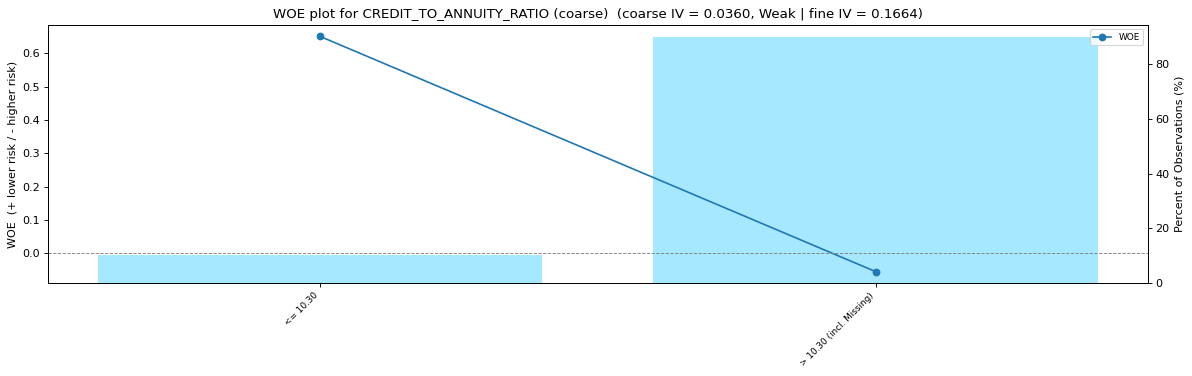

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
<= 10.30,"15,289",10.24%,660,4.32%,+0.6509,0.0332
> 10.30 (incl. Missing),"134,029",89.76%,"11,228",8.38%,-0.0554,0.0028


#### EMPLOYMENT_YEARS  
coarse IV = 0.1155, Medium | fine IV = 0.1185 | 7 groups | Monotonic: risk falls along the groups

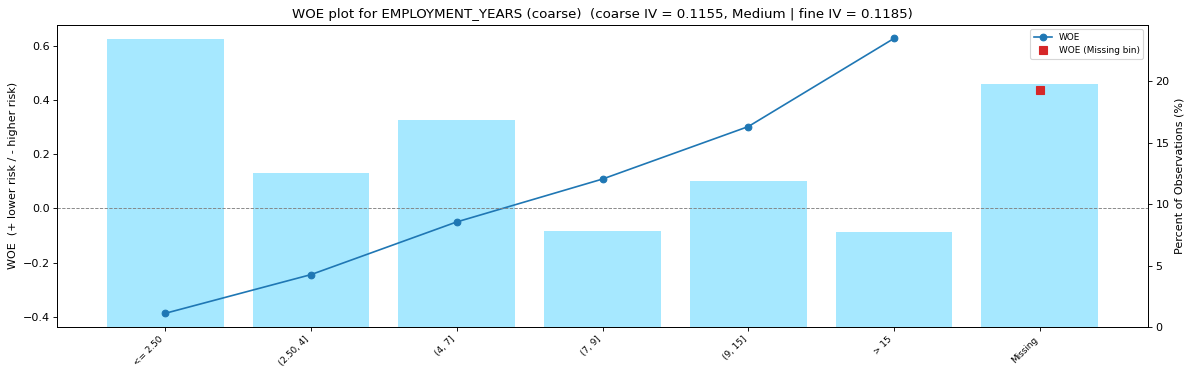

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
<= 2.50,"34,969",23.42%,"3,952",11.30%,-0.3873,0.0413
"(2.50, 4]","18,752",12.56%,"1,865",9.95%,-0.2443,0.0083
"(4, 7]","25,113",16.82%,"2,093",8.33%,-0.0498,0.0004
"(7, 9]","11,622",7.78%,837,7.20%,+0.1085,0.0009
"(9, 15]","17,721",11.87%,"1,065",6.01%,+0.3022,0.0096
> 15,"11,578",7.75%,511,4.41%,+0.6278,0.0236
Missing,"29,563",19.80%,"1,565",5.29%,+0.4367,0.0315


#### CREDIT_TO_GOODS_RATIO  
coarse IV = 0.0833, Weak | fine IV = 0.1005 | 4 groups | Monotonic: risk rises along the groups

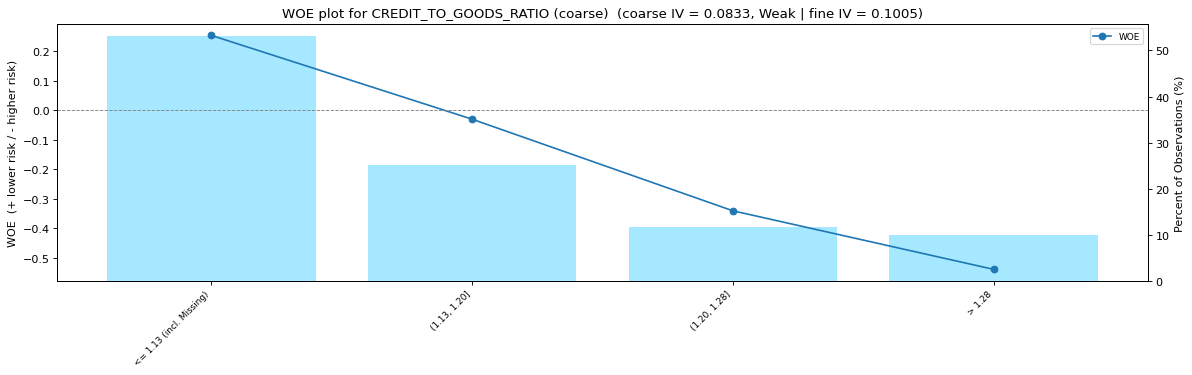

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
<= 1.13 (incl. Missing),"79,330",53.13%,"4,988",6.29%,+0.2541,0.0308
"(1.13, 1.20]","37,634",25.20%,"3,081",8.19%,-0.0303,0.0002
"(1.20, 1.28]","17,460",11.69%,"1,894",10.85%,-0.3412,0.0157
> 1.28,"14,894",9.97%,"1,925",12.92%,-0.5399,0.0365


#### ACTIVE_LOAN_RATIO  
coarse IV = 0.0898, Weak | fine IV = 0.0964 | 6 groups | Monotonic: risk rises along the groups

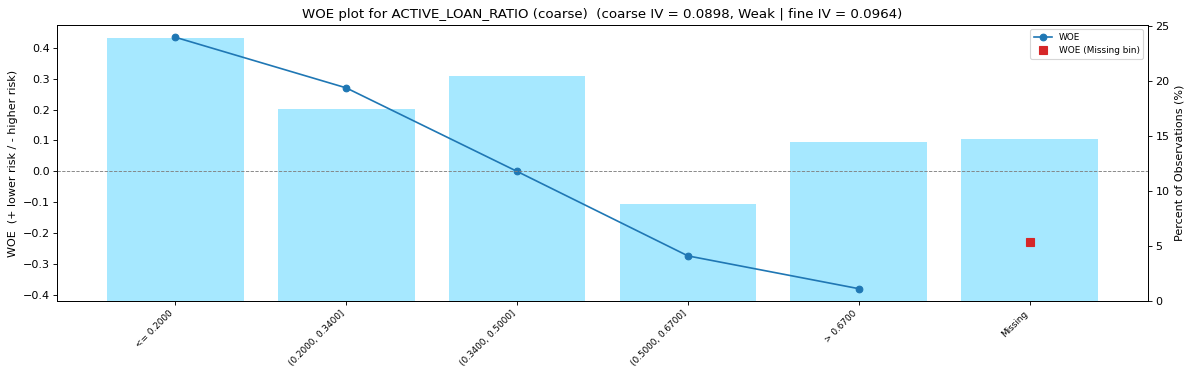

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
<= 0.2000,"35,789",23.97%,"1,898",5.30%,+0.4348,0.0378
"(0.2000, 0.3400]","26,055",17.45%,"1,613",6.19%,+0.2706,0.0114
"(0.3400, 0.5000]","30,577",20.48%,"2,435",7.96%,-0.0003,0.0000
"(0.5000, 0.6700]","13,271",8.89%,"1,356",10.22%,-0.2743,0.0075
> 0.6700,"21,645",14.50%,"2,432",11.24%,-0.3807,0.0247
Missing,"21,981",14.72%,"2,154",9.80%,-0.2279,0.0084


#### MOST_RECENT_CREDIT_AGE  
coarse IV = 0.0890, Weak | fine IV = 0.0932 | 5 groups | Monotonic: risk falls along the groups

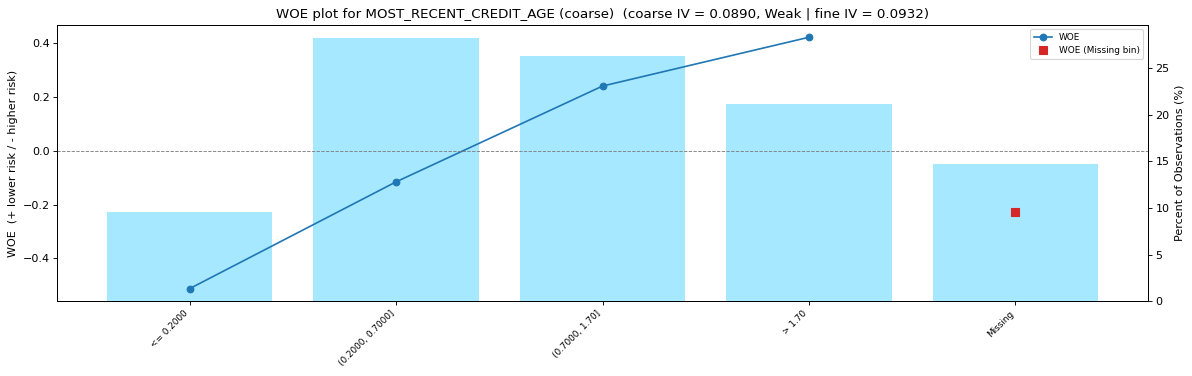

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
<= 0.2000,"14,280",9.56%,"1,803",12.63%,-0.5132,0.0312
"(0.2000, 0.7000]","42,181",28.25%,"3,734",8.85%,-0.1158,0.0040
"(0.7000, 1.70]","39,327",26.34%,"2,504",6.37%,+0.2406,0.0138
> 1.70,"31,549",21.13%,"1,693",5.37%,+0.4223,0.0316
Missing,"21,981",14.72%,"2,154",9.80%,-0.2279,0.0084


#### OCCUPATION_TYPE  
coarse IV = 0.0806, Weak | fine IV = 0.0849 | 4 groups | Monotonic: risk rises along the groups

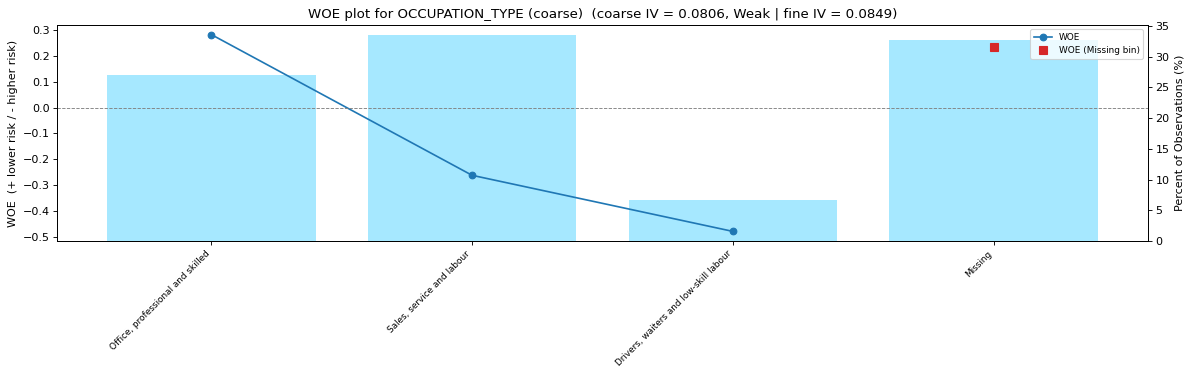

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
"Office, professional and skilled","40,320",27.00%,"2,465",6.11%,+0.2840,0.0193
"Sales, service and labour","50,043",33.51%,"5,058",10.11%,-0.2622,0.0257
"Drivers, waiters and low-skill labour","10,111",6.77%,"1,240",12.26%,-0.4799,0.0191
Missing,"48,844",32.71%,"3,125",6.40%,+0.2355,0.0164


#### OLDEST_CREDIT_AGE  
coarse IV = 0.0737, Weak | fine IV = 0.0803 | 5 groups | Monotonic: risk falls along the groups

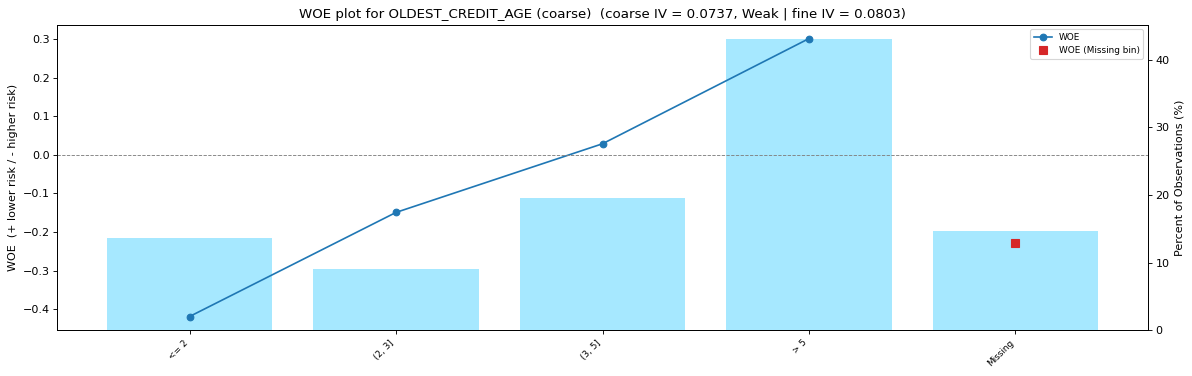

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
<= 2,"20,468",13.71%,"2,378",11.62%,-0.4185,0.0286
"(2, 3]","13,514",9.05%,"1,233",9.12%,-0.1490,0.0021
"(3, 5]","29,148",19.52%,"2,260",7.75%,+0.0287,0.0002
> 5,"64,207",43.00%,"3,863",6.02%,+0.3010,0.0344
Missing,"21,981",14.72%,"2,154",9.80%,-0.2279,0.0084


#### ACTIVE_LOAN_COUNT  
coarse IV = 0.0572, Weak | fine IV = 0.0634 | 5 groups | Monotonic: risk rises along the groups

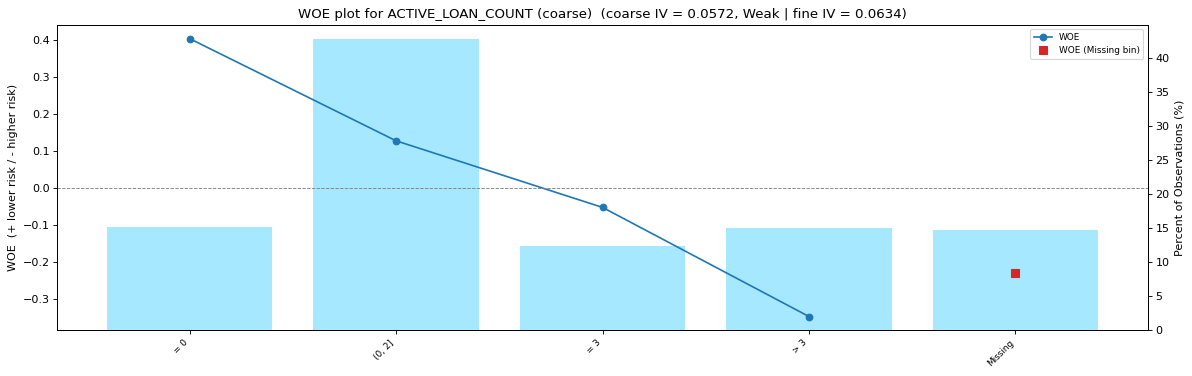

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
= 0,"22,605",15.14%,"1,234",5.46%,+0.4042,0.0209
"(0, 2]","63,842",42.76%,"4,514",7.07%,+0.1283,0.0067
= 3,"18,402",12.32%,"1,536",8.35%,-0.0515,0.0003
> 3,"22,488",15.06%,"2,450",10.89%,-0.3460,0.0209
Missing,"21,981",14.72%,"2,154",9.80%,-0.2279,0.0084


#### NAME_INCOME_TYPE  
coarse IV = 0.0605, Weak | fine IV = 0.0622 | 3 groups | Monotonic: risk rises along the groups

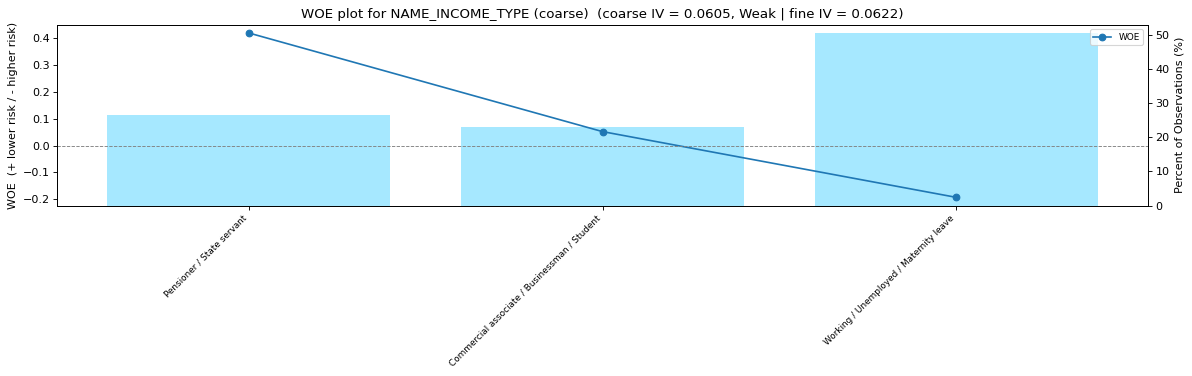

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
Pensioner / State servant,"39,638",26.55%,"2,130",5.37%,+0.4208,0.0395
Commercial associate / Businessman / Student,"34,371",23.02%,"2,607",7.58%,+0.0525,0.0006
Working / Unemployed / Maternity leave,"75,309",50.44%,"7,151",9.50%,-0.1930,0.0204


#### DEBT_TO_CREDIT_RATIO  
coarse IV = 0.0600, Weak | fine IV = 0.0619 | 6 groups | Monotonic: risk rises along the groups

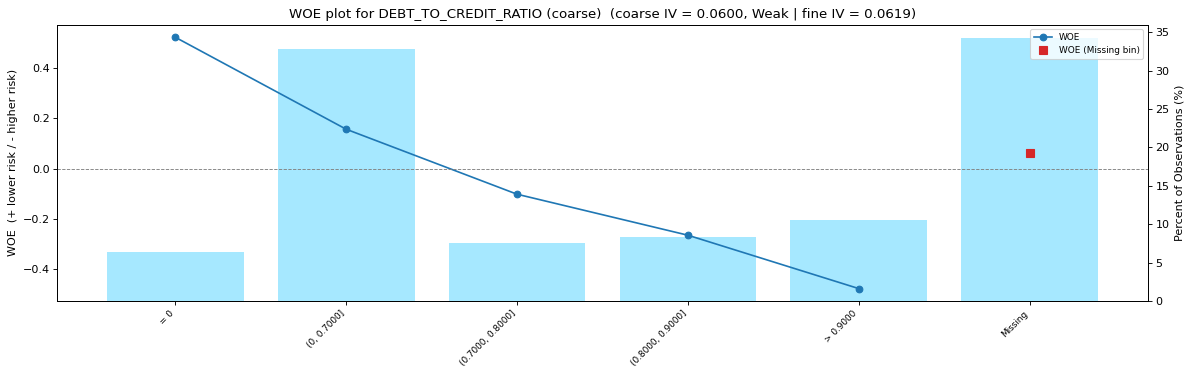

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
= 0,"9,480",6.35%,462,4.87%,+0.5238,0.0140
"(0, 0.7000]","49,000",32.82%,"3,374",6.89%,+0.1568,0.0076
"(0.7000, 0.8000]","11,365",7.61%,994,8.75%,-0.1026,0.0008
"(0.8000, 0.9000]","12,511",8.38%,"1,269",10.14%,-0.2662,0.0066
> 0.9000,"15,788",10.57%,"1,935",12.26%,-0.4792,0.0297
Missing,"51,174",34.27%,"3,854",7.53%,+0.0602,0.0012


#### BUREAU_DEBT_TO_INCOME  
coarse IV = 0.0490, Weak | fine IV = 0.0497 | 5 groups | Monotonic: risk rises along the groups

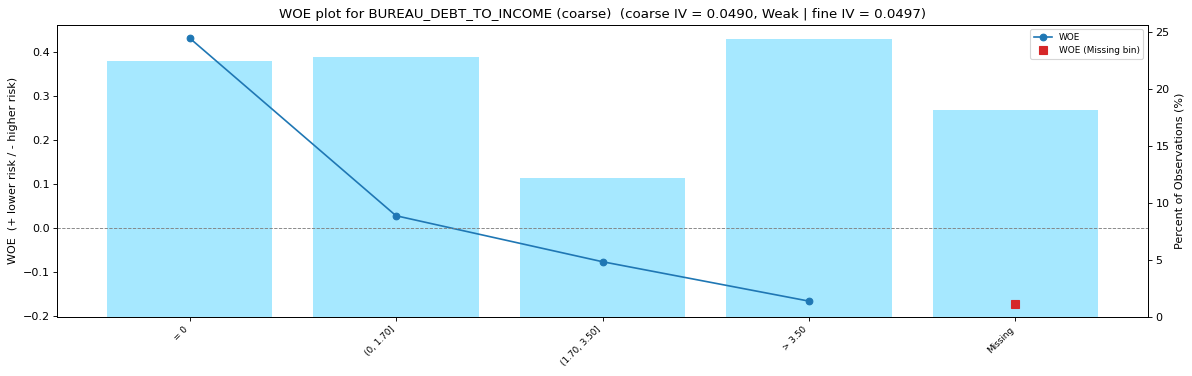

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
= 0,"33,539",22.46%,"1,784",5.32%,+0.4316,0.0350
"(0, 1.70]","34,007",22.77%,"2,640",7.76%,+0.0274,0.0002
"(1.70, 3.50]","18,243",12.22%,"1,559",8.55%,-0.0772,0.0008
> 3.50,"36,452",24.41%,"3,380",9.27%,-0.1668,0.0073
Missing,"27,077",18.13%,"2,525",9.33%,-0.1730,0.0058


#### NAME_EDUCATION_TYPE  
coarse IV = 0.0461, Weak | fine IV = 0.0467 | 3 groups | Monotonic: risk rises along the groups

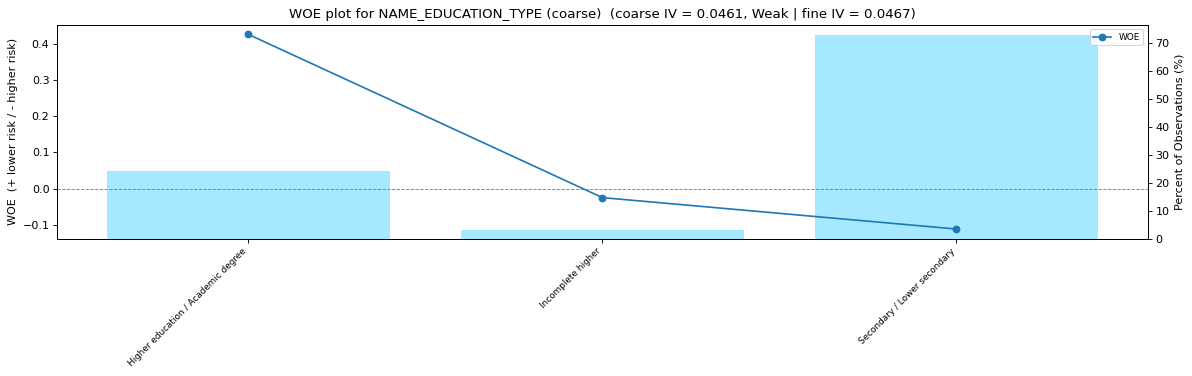

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
Higher education / Academic degree,"35,925",24.06%,"1,921",5.35%,+0.4260,0.0366
Incomplete higher,"4,580",3.07%,373,8.14%,-0.0247,0.0000
Secondary / Lower secondary,"108,813",72.87%,"9,594",8.82%,-0.1114,0.0095


#### MICROLOAN_COUNT  
coarse IV = 0.0284, Weak | fine IV = 0.0284 | 3 groups | Monotonic: risk rises along the groups

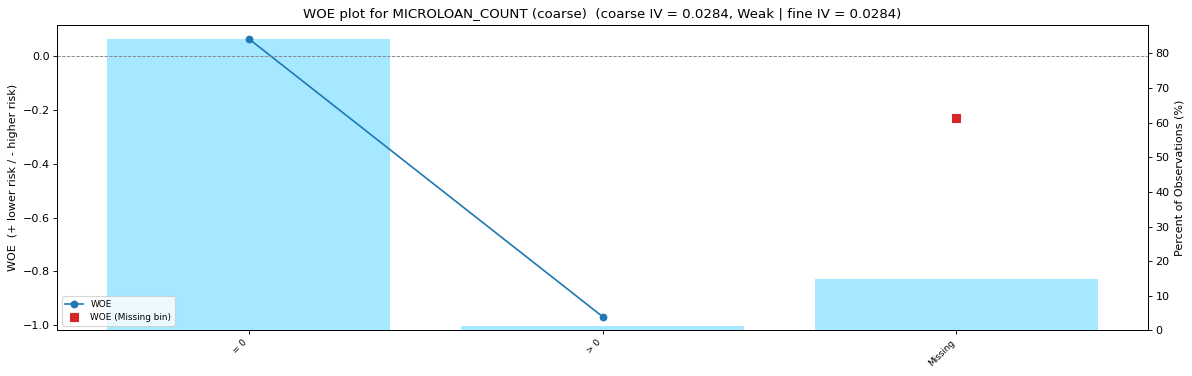

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
= 0,"125,585",84.11%,"9,409",7.49%,+0.0659,0.0035
> 0,"1,752",1.17%,325,18.55%,-0.9681,0.0164
Missing,"21,981",14.72%,"2,154",9.80%,-0.2279,0.0084


#### OVERDUE_LOAN_COUNT  
coarse IV = 0.0188, No predictive power | fine IV = 0.0188 | 3 groups | Monotonic: risk rises along the groups

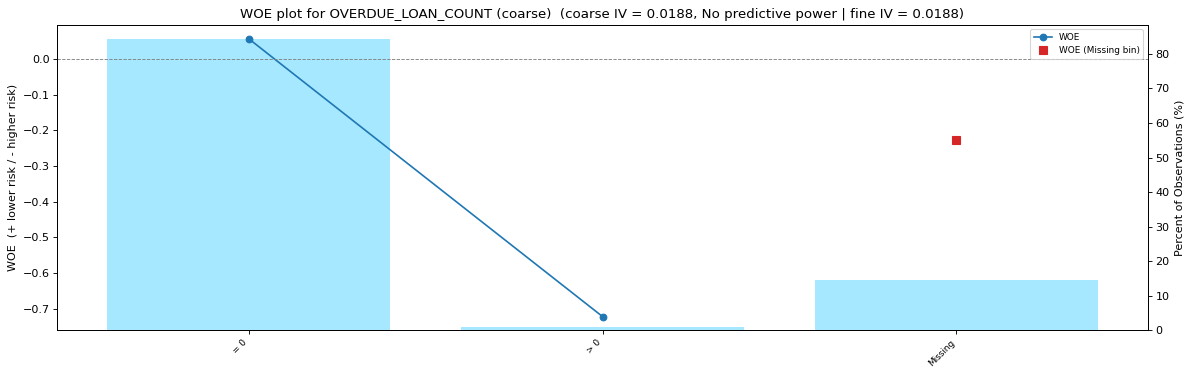

Bin_Range,Count,%_of_Obs,Events,Bad_Rate,WOE,IV
= 0,"125,723",84.20%,"9,490",7.55%,+0.0578,0.0027
> 0,"1,614",1.08%,244,15.12%,-0.7222,0.0076
Missing,"21,981",14.72%,"2,154",9.80%,-0.2279,0.0084


In [26]:
coarse_tables, coarse_rows = {}, []
fine_iv = ranking.set_index('Characteristic')['Fine IV']
for variable in CANDIDATES:
    variable_data = woe_iv(coarse_class(train, variable))
    coarse_tables[variable] = variable_data
    iv = variable_data['total_IV'].iloc[0]
    direction = monotonic_direction(variable_data)
    coarse_rows.append({'Characteristic': variable, 'Fine IV': fine_iv[variable], 'Coarse IV': iv,
                        'IV kept': iv / fine_iv[variable], 'Fine bins': int(ranking.set_index('Characteristic').loc[variable, 'Number of bins']),
                        'Coarse groups': len(variable_data), 'Coarse strength': iv_class(iv), 'WOE trend': direction,
                        'Smallest group %': variable_data['%_of_Obs'].min(), 'Zero-event groups': int(variable_data['Zero_Cell'].sum())})

    iv_text = f'coarse IV = {iv:.4f}, {iv_class(iv)} | fine IV = {fine_iv[variable]:.4f}'
    display(Markdown(f'#### {variable}  \n{iv_text} | {len(variable_data)} groups | {direction}'))
    woe_iv_plot(variable_data, variable + ' (coarse)', iv_text, categorical=False)
    display(variable_data[['Bin_Range', 'Count', '%_of_Obs', 'Events', 'Bad_Rate', 'WOE', 'IV']]
            .style.format({'Count': '{:,}', '%_of_Obs': '{:.2%}', 'Events': '{:,}', 'Bad_Rate': '{:.2%}',
                           'WOE': '{:+.4f}', 'IV': '{:.4f}'}).hide(axis='index'))

coarse_summary = pd.DataFrame(coarse_rows)

### Monotonicity check and fine vs coarse IV

All 14 candidates have a monotonic WOE across their ordered coarse groups, and no group has zero bads or zero goods.


,Characteristic,Fine IV,Coarse IV,IV kept,Fine bins,Coarse groups,Coarse strength,WOE trend,Smallest group %,Zero-event groups
Rank,,,,,,,,,,
1,EMPLOYMENT_YEARS,0.1185,0.1155,98%,21,7,Medium,Monotonic: risk falls along the groups,7.8%,0
2,ACTIVE_LOAN_RATIO,0.0964,0.0898,93%,17,6,Weak,Monotonic: risk rises along the groups,8.9%,0
3,MOST_RECENT_CREDIT_AGE,0.0932,0.0890,96%,21,5,Weak,Monotonic: risk falls along the groups,9.6%,0
4,CREDIT_TO_GOODS_RATIO,0.1005,0.0833,83%,16,4,Weak,Monotonic: risk rises along the groups,10.0%,0
5,OCCUPATION_TYPE,0.0849,0.0806,95%,19,4,Weak,Monotonic: risk rises along the groups,6.8%,0
6,OLDEST_CREDIT_AGE,0.0803,0.0737,92%,21,5,Weak,Monotonic: risk falls along the groups,9.1%,0
7,NAME_INCOME_TYPE,0.0622,0.0605,97%,8,3,Weak,Monotonic: risk rises along the groups,23.0%,0
8,DEBT_TO_CREDIT_RATIO,0.0619,0.0600,97%,20,6,Weak,Monotonic: risk rises along the groups,6.3%,0
9,ACTIVE_LOAN_COUNT,0.0634,0.0572,90%,8,5,Weak,Monotonic: risk rises along the groups,12.3%,0


,Candidates (coarse IV)
Coarse strength,
No predictive power,1
Weak,12
Medium,1
Strong,0
Requires further investigation,0
Not evaluable,0


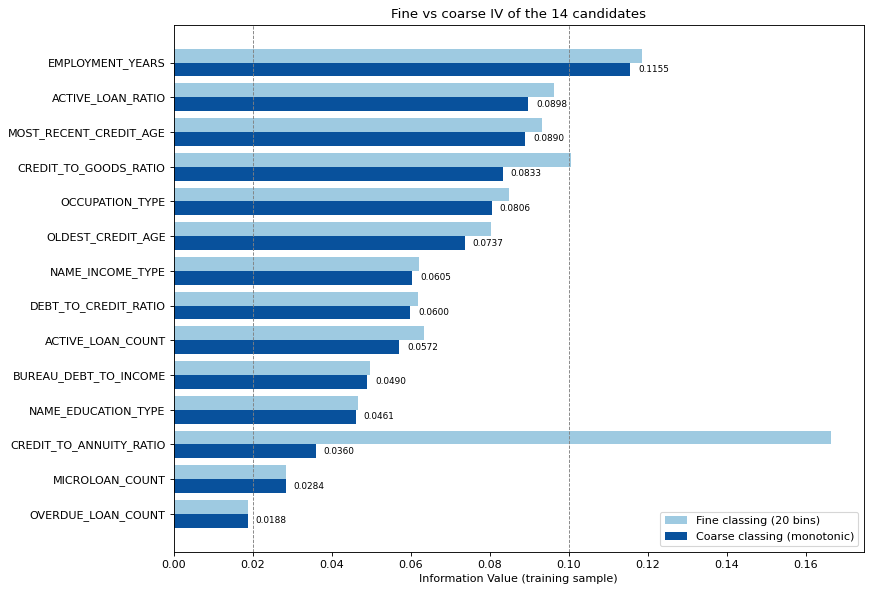

In [27]:
assert (coarse_summary['WOE trend'].str.startswith('Monotonic')).all(), coarse_summary.loc[~coarse_summary['WOE trend'].str.startswith('Monotonic')]
assert (coarse_summary['Zero-event groups'] == 0).all()
print(f'All {len(CANDIDATES)} candidates have a monotonic WOE across their ordered coarse groups, and no group has zero bads or zero goods.')

comparison = coarse_summary.sort_values('Coarse IV', ascending=False).reset_index(drop=True)
comparison.insert(0, 'Rank', np.arange(1, len(comparison) + 1))
display(comparison.set_index('Rank').style.format({'Fine IV': '{:.4f}', 'Coarse IV': '{:.4f}', 'IV kept': '{:.0%}', 'Smallest group %': '{:.1%}'}))
display(comparison['Coarse strength'].value_counts().reindex(classes, fill_value=0).to_frame('Candidates (coarse IV)'))

# fine vs coarse IV
plot_data = comparison.iloc[::-1]
y = np.arange(len(plot_data))
fig, ax = plt.subplots(figsize=(11, 7.5))
ax.barh(y + 0.2, plot_data['Fine IV'], height=0.4, color='#9ecae1', label='Fine classing (20 bins)')
ax.barh(y - 0.2, plot_data['Coarse IV'], height=0.4, color='#08519c', label='Coarse classing (monotonic)')
for yy, v in zip(y, plot_data['Coarse IV']):
    ax.text(v + 0.002, yy - 0.2, f'{v:.4f}', va='center', fontsize=8)
for t in (0.02, 0.10):
    ax.axvline(t, color='grey', linestyle='--', linewidth=0.8)
ax.set_yticks(y)
ax.set_yticklabels(plot_data['Characteristic'])
ax.set_xlabel('Information Value (training sample)')
ax.set_title(f'Fine vs coarse IV of the {len(CANDIDATES)} candidates')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

**What we found**

- **All 14 candidates have a monotonic WOE** across their ordered groups, and every group has both goods and bads. The only groups below 3% of applicants are the rare-signal ones: any microloan (1.2%) and current arrears (1.1%). We keep them separate on purpose, because they double the bad rate.
- **Most characteristics keep almost all their information.** Twelve candidates keep 90%-100% of their fine IV, and `CREDIT_TO_GOODS_RATIO` keeps 83%. Simpler groups cost very little predictive power.
- **Two candidates do not hold up once grouped monotonically:**
  - `CREDIT_TO_ANNUITY_RATIO` falls from 0.166 to **0.036**, keeping only 22%. Its risk depends on specific repayment terms rather than rising or falling with the ratio (5.6C), so the only monotonic grouping is "10.3 or below" vs "above".
  - `OVERDUE_LOAN_COUNT` (**0.019**) ends up below the 0.02 threshold.
- **We use these results for the final selection in 5.8D.**

## 5.8D Final Selection and Export

Coarse classing shows how much predictive power each candidate keeps once its groups are monotonic. We agreed two rules to finish the selection:

| Rule | Threshold | Why |
|---|---|---|
| **Low predictive power** | Coarse IV below **0.02** | The same IV threshold as the screening in 5.6A, applied to the groups the scorecard will actually use |
| **Signal lost under monotonic grouping** | Coarse IV below **25%** of the fine IV | The risk pattern is not ordered, so monotonic groups keep too little of it. For `CREDIT_TO_ANNUITY_RATIO`, the pattern follows specific repayment terms (product pricing) rather than rising or falling with the ratio (5.6C) |

We export the final characteristics to `data/final_characteristics.csv` with their **raw** prepared values (no grouping, no WOE), and their groups and WOE values to `data/coarse_classing_bins.json` for the scorecard step.

In [28]:
COARSE_IV_MIN = 0.02
IV_KEPT_MIN = 0.25
by_char = coarse_summary.set_index('Characteristic')
COARSE_DROPS = {}
for c in CANDIDATES:
    r = by_char.loc[c]
    if r['Coarse IV'] < COARSE_IV_MIN:
        COARSE_DROPS[c] = ('Low predictive power', f"Coarse IV {r['Coarse IV']:.4f} (< 0.02) after monotonic grouping")
    elif r['IV kept'] < IV_KEPT_MIN:
        COARSE_DROPS[c] = ('Signal lost under monotonic grouping', f"Coarse IV {r['Coarse IV']:.4f} keeps only {r['IV kept']:.0%} of fine IV {r['Fine IV']:.4f}")

FINAL_CHARACTERISTICS = [c for c in CANDIDATES if c not in COARSE_DROPS]
assert len(FINAL_CHARACTERISTICS) == 12

display(pd.DataFrame([{'Characteristic': c, 'Category': cat, 'Evidence': ev} for c, (cat, ev) in COARSE_DROPS.items()]).set_index('Characteristic'))
final_view = by_char.loc[FINAL_CHARACTERISTICS, ['Fine IV', 'Coarse IV', 'Coarse groups', 'Coarse strength', 'WOE trend']].sort_values('Coarse IV', ascending=False)
display(Markdown(f'**Final characteristics ({len(FINAL_CHARACTERISTICS)})**'))
display(final_view.style.format({'Fine IV': '{:.4f}', 'Coarse IV': '{:.4f}'}))

,Category,Evidence
Characteristic,,
CREDIT_TO_ANNUITY_RATIO,Signal lost under monotonic grouping,Coarse IV 0.0360 keeps only 22% of fine IV 0.1664
OVERDUE_LOAN_COUNT,Low predictive power,Coarse IV 0.0188 (< 0.02) after monotonic grouping


**Final characteristics (12)**

,Fine IV,Coarse IV,Coarse groups,Coarse strength,WOE trend
Characteristic,,,,,
EMPLOYMENT_YEARS,0.1185,0.1155,7,Medium,Monotonic: risk falls along the groups
ACTIVE_LOAN_RATIO,0.0964,0.0898,6,Weak,Monotonic: risk rises along the groups
MOST_RECENT_CREDIT_AGE,0.0932,0.0890,5,Weak,Monotonic: risk falls along the groups
CREDIT_TO_GOODS_RATIO,0.1005,0.0833,4,Weak,Monotonic: risk rises along the groups
OCCUPATION_TYPE,0.0849,0.0806,4,Weak,Monotonic: risk rises along the groups
OLDEST_CREDIT_AGE,0.0803,0.0737,5,Weak,Monotonic: risk falls along the groups
NAME_INCOME_TYPE,0.0622,0.0605,3,Weak,Monotonic: risk rises along the groups
DEBT_TO_CREDIT_RATIO,0.0619,0.0600,6,Weak,Monotonic: risk rises along the groups
ACTIVE_LOAN_COUNT,0.0634,0.0572,5,Weak,Monotonic: risk rises along the groups


### Removal summary (30 prepared characteristics to 12)

In [29]:
ALL_DROPS = {**{c: ('Screening (5.6B-5.6C)',) + v for c, v in SCREENING_DROPS.items()},
             **{c: ('After coarse classing (5.8D)',) + v for c, v in COARSE_DROPS.items()}}
removal = pd.DataFrame([{'Characteristic': c, 'Stage': s, 'Reason': cat, 'Evidence': ev,
                         'Fine IV': fine_iv[c]} for c, (s, cat, ev) in ALL_DROPS.items()])
removal = removal.sort_values(['Reason', 'Fine IV'], ascending=[True, False]).reset_index(drop=True)
display(removal.set_index('Characteristic').style.format({'Fine IV': '{:.4f}'}))

reason_counts = removal.groupby(['Reason', 'Stage']).size().unstack(fill_value=0)
reason_counts['Total'] = reason_counts.sum(axis=1)
display(reason_counts)

flow = pd.DataFrame({'Characteristics': {
    'Prepared candidates (Step 4)': len(characteristics),
    'Removed at screening': len(SCREENING_DROPS),
    'Coarse-classed candidates': len(CANDIDATES),
    'Removed after coarse classing': len(COARSE_DROPS),
    'Final characteristics': len(FINAL_CHARACTERISTICS)}})
display(flow)
assert len(removal) + len(FINAL_CHARACTERISTICS) == len(characteristics)

,Stage,Reason,Evidence,Fine IV
Characteristic,,,,
OVERDUE_LOAN_COUNT,After coarse classing (5.8D),Low predictive power,Coarse IV 0.0188 (< 0.02) after monotonic grouping,0.0188
MORTGAGE_COUNT,Screening (5.6B-5.6C),Low predictive power,Fine IV 0.018 (< 0.02),0.0176
NAME_CONTRACT_TYPE,Screening (5.6B-5.6C),Low predictive power,Fine IV 0.016 (< 0.02); revolving loans also identified by CREDIT_TO_ANNUITY_RATIO = 20,0.0164
BUREAU_LOAN_COUNT,Screening (5.6B-5.6C),Low predictive power,"Fine IV 0.015 (< 0.02), mostly from the Missing bin",0.0149
TOTAL_BUREAU_ENQUIRIES_12M,Screening (5.6B-5.6C),Low predictive power,"Fine IV 0.015 (< 0.02), mostly from the Missing bin",0.0148
ADVERSE_STATUS_COUNT,Screening (5.6B-5.6C),Low predictive power,"Fine IV 0.012 (< 0.02), mostly from the Missing bin",0.0120
LOAN_TO_INCOME,Screening (5.6B-5.6C),Low predictive power,Fine IV 0.011 (< 0.02),0.0113
AMT_INCOME_TOTAL,Screening (5.6B-5.6C),Low predictive power,Fine IV 0.011 (< 0.02),0.0106
TOTAL_PROLONGATIONS,Screening (5.6B-5.6C),Low predictive power,"Fine IV 0.010 (< 0.02), mostly from the Missing bin",0.0104


Stage,After coarse classing (5.8D),Screening (5.6B-5.6C),Total
Reason,,,
Low predictive power,1,11,12
Redundant,0,4,4
Signal lost under monotonic grouping,1,1,2


,Characteristics
Prepared candidates (Step 4),30
Removed at screening,16
Coarse-classed candidates,14
Removed after coarse classing,2
Final characteristics,12


In [30]:
import json

# export the final characteristics with their raw prepared values (values untouched)
original = pd.read_csv('data/prepared_data.csv')
final_characteristics = original[[ID, TARGET] + FINAL_CHARACTERISTICS]
final_characteristics.to_csv('data/final_characteristics.csv', index=False)

saved = pd.read_csv('data/final_characteristics.csv')
validation = {
    'Row count matches prepared_data.csv': len(saved) == len(original),
    'Every SK_ID_CURR unique': saved[ID].is_unique,
    'Same applicants as prepared_data.csv': set(saved[ID]) == set(original[ID]),
    'TARGET unchanged': saved[TARGET].equals(original[TARGET]),
    f'Columns = ID + TARGET + the {len(FINAL_CHARACTERISTICS)} final characteristics': list(saved.columns) == [ID, TARGET] + FINAL_CHARACTERISTICS,
    'No removed characteristic present': not set(ALL_DROPS) & set(saved.columns),
    'No other characteristic removed': set(original.columns) - set(saved.columns) == set(ALL_DROPS),
    'No duplicate columns': saved.columns.is_unique,
    'Values identical to prepared_data.csv (incl. missing)': saved[FINAL_CHARACTERISTICS].equals(original[FINAL_CHARACTERISTICS]),
}
display(pd.DataFrame({'Passed': validation}))
assert all(validation.values())

# save the approved coarse groups and WOE of the final characteristics for the scorecard step
coarse_definition = {
    'fitted_on': 'training sample (sc.split_df ratio 0.7, seed 186; data/train_test_split.csv)',
    'approved': APPROVAL_DATE,
    'numeric_edges_right_closed': {k: [None if np.isinf(e) else e for e in v] for k, v in COARSE_EDGES.items() if k in FINAL_CHARACTERISTICS},
    'category_groups': {k: v for k, v in CATEGORY_GROUPS.items() if k in FINAL_CHARACTERISTICS},
    'missing_merged_into_group_position': {k: v for k, v in MISSING_INTO.items() if k in FINAL_CHARACTERISTICS},
    'missing_otherwise': 'own group',
    'woe': {v: dict(zip(coarse_tables[v]['Bin_Range'], coarse_tables[v]['WOE'].round(6))) for v in FINAL_CHARACTERISTICS},
    'coarse_iv': {v: round(float(coarse_tables[v]['total_IV'].iloc[0]), 6) for v in FINAL_CHARACTERISTICS},
}
with open('data/coarse_classing_bins.json', 'w') as f:
    json.dump(coarse_definition, f, indent=2)

final_summary = pd.DataFrame({'Result': {
    'Prepared candidate characteristics': len(characteristics),
    'Removed characteristics': len(ALL_DROPS),
    'Final characteristics': len(FINAL_CHARACTERISTICS),
    'Applicants (prepared / final)': f'{len(original):,} / {len(saved):,}',
    'Bad rate (prepared / final)': f'{original[TARGET].mean():.2%} / {saved[TARGET].mean():.2%}',
}})
display(final_summary)
print('Saved data/final_characteristics.csv', saved.shape, 'and data/coarse_classing_bins.json')

assert fingerprint(prepared) == prepared_fingerprint
del original, saved

,Passed
Row count matches prepared_data.csv,True
Every SK_ID_CURR unique,True
Same applicants as prepared_data.csv,True
TARGET unchanged,True
Columns = ID + TARGET + the 12 final characteristics,True
No removed characteristic present,True
No other characteristic removed,True
No duplicate columns,True
Values identical to prepared_data.csv (incl. missing),True


,Result
Prepared candidate characteristics,30
Removed characteristics,18
Final characteristics,12
Applicants (prepared / final),"213,312 / 213,312"
Bad rate (prepared / final),7.96% / 7.96%


Saved data/final_characteristics.csv (213312, 14) and data/coarse_classing_bins.json


**What we ended up with**

- **Final set: 12 characteristics,** all with a monotonic WOE that makes sense and coarse IV between 0.028 and 0.116:
  - job stability: `EMPLOYMENT_YEARS`, `OCCUPATION_TYPE`, `NAME_INCOME_TYPE`
  - loan structure: `CREDIT_TO_GOODS_RATIO`
  - existing credit exposure: `ACTIVE_LOAN_RATIO`, `ACTIVE_LOAN_COUNT`, `DEBT_TO_CREDIT_RATIO`, `BUREAU_DEBT_TO_INCOME`
  - credit history: `MOST_RECENT_CREDIT_AGE`, `OLDEST_CREDIT_AGE`
  - applicant profile: `NAME_EDUCATION_TYPE`
  - financial stress: `MICROLOAN_COUNT`
- **We removed 18 of the 30 prepared characteristics, for three reasons:**
  - **Low predictive power (12):** IV below 0.02. Eleven at screening and one after coarse classing (`OVERDUE_LOAN_COUNT`).
  - **Redundancy (4):** a stronger characteristic already carries the information.
  - **Signal lost under monotonic grouping (2):** `AMT_CREDIT` and `CREDIT_TO_ANNUITY_RATIO`. Their risk pattern is not ordered, so a monotonic scorecard cannot use it.
- **Arrears.** All the bureau arrears measures fell below the predictive-power threshold (we had already removed `MAX_HIST_OVERDUE` in Step 4 for being more than 40% missing). So past repayment problems only come in indirectly, through credit exposure, recent credit activity and microloans. We will state this as a limitation in our presentation.
- **Outputs.**
  - `final_characteristics.csv` holds the raw values of the 12 characteristics for all 213,312 applicants. The bad rate is still 7.96%, and no value has been changed.
  - `coarse_classing_bins.json` holds their groups and WOE for Step 6.